<a id="top"></a>
# Продуктовая аналитика магазина косметики
Этап PA-S1 · индивидуальный трек Б · REES46 · октябрь 2019 — февраль 2020

[Репозиторий проекта](https://github.com/7drezz/cosmetics-product-analytics)

**Вопрос:** как повысить ранние покупки и сохранить возврат пользователей?

За пять месяцев записано **20 692 840 событий** от **1 639 358 user_id**. Покупатели за неделю (WBU: уникальные пользователи с `purchase` за календарную неделю) — **6 910,2** в среднем. Конверсия за первые 7 дней (CR7: ≥1 `purchase` в дни 0–6) — **4,77%**. Удержание на четвёртой неделе (R4: любое событие в дни 28–34) — **3,38%**. Стоимость событий `purchase` за первые 30 дней на пользователя (V30) — **2,6315** в единицах исходного `price`.

Денежные показатели и каналы отделены от наблюдений. Цели ещё не проверялись экспериментом.

[Данные](#data) · [Определения](#definitions) · [Метрики](#metrics) · [Результаты](#analysis) · [Экономика](#economics) · [Цели](#targets) · [Запуск](#reproducibility) · [Приложение](#appendix)

## 1. Продукт и гипотеза

Это интернет-магазин косметики; бизнес-модель — продажа товаров. Сам магазин и его интерфейс в данных не описаны. Исследуем пользователей с первым наблюдаемым событием; это не подтверждённые новые клиенты.

**Изменение:** показывать стоимость и условия доставки в корзине до оформления заказа. **Гипотеза:** ясные условия доставки помогут большему числу пользователей совершить `purchase` в первые 7 дней. Данные не доказывают, что доставка сейчас вызывает отказ.

**Проверка:** A/B-тест с назначением варианта до взаимодействия с корзиной. Основной результат — CR7; дополнительно отслеживать R4 и покупку в дни 7–96 у всех назначенных. Исторические данные дают baseline, но не измеряют эффект изменения.

<a id="data"></a>
## 2. Данные и качество

[Kaggle](https://www.kaggle.com/datasets/mkechinov/ecommerce-events-history-in-cosmetics-shop) · [REES46](https://rees46.com/en/datasets). Пять CSV охватывают 152 дня по UTC и занимают около 2,43 ГБ. Хэши снимка сохранены. На Kaggle указано «Data files © Original Authors»; отдельная открытая лицензия и разрешение на перепубликацию не указаны. Официальный номер версии не подтверждён.

| Наблюдение | Правило | Влияние |
|---|---|---|
| 1 109 098 лишних копий полных совпадений (5,36%) | Сохранить; проверить вариант с одной копией | Активность пользователей не меняется; V30 меняется на −0,054% |
| 131 отрицательная цена, 126 у `purchase` | Событие оставить; цену исключить из основного V30 | Без фильтра V30 ниже на 0,068% |
| Нули и высокие цены | Сохранить; отдельно ограничить по 99,9-му перцентилю | Ограничение меняет V30 на −1,21% |
| Часто пусты `category_code` (98,3%) и `brand` (42,3%) | Не угадывать; использовать `category_id`, неизвестные значения оставить отдельно | Товарные срезы ограничены |
| 4 598 событий без `user_session`; часть сессий длиннее суток | Метрики считать по пользователям и календарным неделям | Результаты не зависят от эвристики сессии |
| Нет списка тестовых пользователей | Не исключать; частотную эвристику показывать только как чувствительность | Нельзя уверенно назвать таких пользователей ботами |
| Все 152 даты есть; ключи разбираются | Проверять файлы, время, типы и соединения | Помогает найти потерю строк или размножение пользователей |

Данные подходят для когортного удержания и временных рядов. В них нет подтверждённых привлечений, каналов, расходов, маржи и оплат. Эти ограничения учтены в экономическом разделе. Подробная методика — в [приложении](#appendix).

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, zipfile, shutil, platform
import importlib.metadata as metadata

ROOT = Path('.')
assert (ROOT / 'data/source_manifest.json').is_file(), 'Запустите ноутбук из корня проекта; см. README.'
for folder in ['tmp', 'tmp/duckdb', 'tmp/matplotlib', 'data/cache', 'outputs/tables', 'outputs/figures']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(ROOT / 'tmp/matplotlib')
os.environ['TMP'] = os.environ['TEMP'] = str(ROOT / 'tmp')

import duckdb
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 35)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.titlesize': 14, 'axes.labelsize': 11, 'savefig.dpi': 160})
STARTED = time.time()
CHECKS = []
APPENDIX = []
MAIN_TABLES = {'success_targets','scenario_ratio_matrix','synthetic_channel_cac',
               'results_brief','risk_summary','control_indicator'}
def check(name, condition, detail=''):
    ok = bool(condition)
    CHECKS.append({'Проверка': name, 'Результат': 'Пройдена' if ok else 'ОШИБКА', 'Подробности': str(detail)})
    if not ok:
        raise AssertionError(f'{name}: {detail}')
def show(df, name, index=False):
    df.to_csv(ROOT / 'outputs/tables' / f'{name}.csv', index=index, encoding='utf-8-sig')
    if name in MAIN_TABLES:
        display(df)
    else:
        APPENDIX.append((name, df.copy()))
def sql(query):
    return con.execute(query).fetchdf()
def scalar(query):
    return con.execute(query).fetchone()[0]
def fmt(x, digits=0):
    return f'{x:,.{digits}f}'.replace(',', ' ').replace('.', ',')
def pct(x, digits=2):
    return fmt(100 * x, digits) + '%'
def savefig(fig, name):
    fig.savefig(ROOT / 'outputs/figures' / f'{name}.png', bbox_inches='tight')
    item=Image(data=(ROOT / 'outputs/figures' / f'{name}.png').read_bytes())
    if name=='value30_cohorts': APPENDIX.append(('График V30 по когортам',item))
    else: display(item)
    plt.close(fig)

versions = {name: metadata.version(name) for name in ['duckdb','pandas','numpy','matplotlib','ipython','ipykernel','nbformat','nbclient','jupyter-client','jupyter-core','jupyterlab','nbconvert']}
versions['python'] = platform.python_version()
(ROOT / 'outputs/runtime_versions.json').write_text(json.dumps(versions, ensure_ascii=False, indent=2), encoding='utf-8')
APPENDIX.append(('runtime_versions', pd.DataFrame(versions.items(), columns=['Компонент', 'Фактическая версия'])))

In [2]:
def sha256_file(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

manifest = json.loads((ROOT / 'data/source_manifest.json').read_text(encoding='utf-8'))
archive = ROOT / 'data/raw/cosmetics.zip'
check('Архив присутствует', archive.is_file())
check('SHA-256 архива', sha256_file(archive) == manifest['sha256'])
FILES = ['2019-Oct.csv','2019-Nov.csv','2019-Dec.csv','2020-Jan.csv','2020-Feb.csv']
COLUMNS = ['event_time','event_type','product_id','category_id','category_code','brand','price','user_id','user_session']
inventory = []
file_issues = []
with zipfile.ZipFile(archive) as z:
    check('Ровно пять исходных CSV', sorted(z.namelist()) == sorted(FILES))
    for filename in FILES:
        info = z.getinfo(filename)
        target = ROOT / 'data/raw' / filename
        # Сверяем байты CSV с содержимым проверенного ZIP, а не только размер файла.
        h = hashlib.sha256()
        if not target.exists():
            with z.open(filename) as source, target.open('wb') as destination:
                for block in iter(lambda: source.read(8 * 1024 * 1024), b''):
                    destination.write(block)
                    h.update(block)
        else:
            with z.open(filename) as source:
                for block in iter(lambda: source.read(8 * 1024 * 1024), b''):
                    h.update(block)
            if sha256_file(target) != h.hexdigest(): file_issues.append(filename + ': SHA-256')
        with target.open(encoding='utf-8-sig') as f:
            if f.readline().strip().split(',') != COLUMNS: file_issues.append(filename + ': схема')
        inventory.append({'Файл': filename, 'Байт CSV': info.file_size, 'SHA-256': h.hexdigest()})
check('Пять CSV совпадают с архивом: хэш и схема', not file_issues, file_issues)
verified_manifest = {'archive_sha256': manifest['sha256'], 'files': inventory}
(ROOT / 'outputs/input_manifest_verified.json').write_text(json.dumps(verified_manifest, ensure_ascii=False, indent=2), encoding='utf-8')
show(pd.DataFrame(inventory), 'input_inventory')
print('Проверены SHA-256 архива и содержимое всех пяти CSV; подробности в приложении.')

Проверены SHA-256 архива и содержимое всех пяти CSV; подробности в приложении.


In [3]:
# Производная база пересоздаётся: выполнение не зависит от имеющегося кеша.
if 'con' in globals():
    con.close()
db_path = ROOT / 'data/cache/analytics.duckdb'
for suffix in ['', '.wal']:
    generated_file = Path(str(db_path) + suffix)
    if generated_file.exists():
        generated_file.unlink()
con = duckdb.connect(str(db_path))
con.execute("SET memory_limit='3GB'")
con.execute("SET threads=1")
con.execute("SET preserve_insertion_order=false")
con.execute("SET temp_directory='tmp/duckdb'")
con.execute("SET TimeZone='UTC'")
con.execute("SET preserve_insertion_order=false")
paths = [str(ROOT / 'data/raw' / filename).replace('\\','/') for filename in FILES]
con.execute('CREATE TABLE raw_events AS SELECT * FROM read_csv(?, header=true, all_varchar=true, filename=true, nullstr=\'\', strict_mode=true)', [paths])
con.execute(r'''
CREATE TABLE events AS
SELECT try_strptime(event_time, '%Y-%m-%d %H:%M:%S UTC') AS event_time,
       try_strptime(event_time, '%Y-%m-%d %H:%M:%S UTC')::DATE AS event_day,
       event_type,
       try_cast(product_id AS BIGINT) AS product_id,
       try_cast(category_id AS BIGINT) AS category_id,
       category_code, brand,
       try_cast(price AS DECIMAL(18,2)) AS price,
       try_cast(user_id AS BIGINT) AS user_id,
       user_session, regexp_extract(filename, '[^/\\]+$') AS source_file
FROM raw_events
''')
check('Импорт не теряет строки', scalar('SELECT count(*) FROM events') == scalar('SELECT count(*) FROM raw_events'))
parse_errors = sql(r'''
SELECT count(*) FILTER (WHERE event_time IS NOT NULL AND try_strptime(event_time, '%Y-%m-%d %H:%M:%S UTC') IS NULL) AS time_errors,
 count(*) FILTER (WHERE user_id IS NOT NULL AND try_cast(user_id AS BIGINT) IS NULL) AS user_errors,
 count(*) FILTER (WHERE product_id IS NOT NULL AND try_cast(product_id AS BIGINT) IS NULL) AS product_errors,
 count(*) FILTER (WHERE category_id IS NOT NULL AND try_cast(category_id AS BIGINT) IS NULL) AS category_errors,
 count(*) FILTER (WHERE price IS NOT NULL AND (try_cast(price AS DECIMAL(18,2)) IS NULL
   OR NOT regexp_full_match(price, '-?[0-9]+(\.[0-9]{1,2})?'))) AS price_errors
FROM raw_events
''')
check('Преобразования без ошибок и округления цены', int(parse_errors.to_numpy().sum()) == 0, parse_errors.to_dict('records'))
event_counts = sql('SELECT event_type AS "Событие", count(*) AS "Строк" FROM events GROUP BY 1 ORDER BY 2 DESC')
check('Известные типы событий', set(event_counts['Событие']) == {'view','cart','remove_from_cart','purchase'})
show(event_counts, 'event_counts')
monthly = sql('''SELECT source_file AS "Файл", count(*) AS "Строк", min(event_time) AS "Первое событие UTC", max(event_time) AS "Последнее событие UTC" FROM events GROUP BY 1 ORDER BY min(event_time)''')
show(monthly, 'monthly_inventory')

In [4]:
nulls = pd.DataFrame([{'Поле': col, 'Пропусков': int(scalar(f'SELECT count(*) FROM raw_events WHERE {col} IS NULL'))} for col in COLUMNS])
N = int(scalar('SELECT count(*) FROM events'))
nulls['Доля, %'] = nulls['Пропусков'] / N * 100
show(nulls, 'missing_values')
check('Нет пропусков ключей активности', nulls.set_index('Поле').loc[['event_time','event_type','user_id','product_id','category_id','price'],'Пропусков'].sum() == 0)

id_checks = sql(r'''
SELECT count(*) FILTER (WHERE user_id<=0) AS "Неположительный user_id",
 count(*) FILTER (WHERE product_id<=0) AS "Неположительный product_id",
 count(*) FILTER (WHERE category_id<=0) AS "Неположительный category_id",
 count(*) FILTER (WHERE user_session IS NOT NULL AND NOT regexp_full_match(user_session,
 '[0-9a-fA-F]{8}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{12}')) AS "Необычный формат сессии"
FROM events
''')
show(id_checks, 'identifier_checks')

price_quality = sql('''
SELECT event_type AS "Событие", count(*) AS "Строк",
 count(*) FILTER(WHERE price<0) AS "Цена < 0", count(*) FILTER(WHERE price=0) AS "Цена = 0",
 min(price)::DOUBLE AS "Минимум", quantile_cont(price,0.5)::DOUBLE AS "Медиана",
 quantile_cont(price,0.99)::DOUBLE AS "P99", quantile_cont(price,0.999)::DOUBLE AS "P99,9", max(price)::DOUBLE AS "Максимум"
FROM events GROUP BY 1 ORDER BY 1
''')
show(price_quality, 'price_quality')
CAP = float(scalar("SELECT quantile_cont(price,0.999) FROM events WHERE event_type='purchase' AND price>=0"))
APPENDIX.append(('Порог чувствительности цены purchase, не порог ошибки', pd.DataFrame({'P99,9': [CAP]})))

In [5]:
raw_cols = ','.join(COLUMNS)
con.execute(f'CREATE TABLE duplicate_groups AS SELECT {raw_cols}, count(*) AS n FROM raw_events GROUP BY {raw_cols} HAVING count(*)>1')
duplicate_summary = sql('''SELECT count(*) AS "Групп совпадений", sum(n-1) AS "Избыточных строк", sum(n) AS "Строк в группах", max(n) AS "Максимум повторений" FROM duplicate_groups''')
duplicate_excess_rows = int(duplicate_summary.iloc[0]['Избыточных строк'])
duplicate_summary['Избыточных, % всех строк'] = duplicate_excess_rows / N * 100
show(duplicate_summary, 'duplicates_summary')
duplicates_types = sql('''SELECT event_type AS "Событие", count(*) AS "Групп", sum(n-1) AS "Избыточных строк" FROM duplicate_groups GROUP BY 1 ORDER BY 3 DESC''')
show(duplicates_types, 'duplicates_by_event')
remove_excess=float(duplicates_types.loc[duplicates_types['Событие']=='remove_from_cart','Избыточных строк'].iloc[0])
purchase_excess=float(duplicates_types.loc[duplicates_types['Событие']=='purchase','Избыточных строк'].iloc[0])
APPENDIX.append(('Пояснение к диагностике',Markdown(f'''**Где сосредоточены совпадения.** {pct(remove_excess/duplicate_excess_rows)} избыточных совпадений относятся к `remove_from_cart`; у `purchase` их {fmt(purchase_excess)}. Поэтому общую долю совпадающих строк нельзя переносить на денежные показатели. Пользовательские флаги «было событие» устойчивы к числу одинаковых копий; суммы по строкам требуют отдельной проверки чувствительности.''')))



#### Пользовательские даты и когорты

In [6]:
con.execute(f'''
CREATE TABLE user_days AS
SELECT user_id, event_day, min(event_time) AS first_time, max(event_time) AS last_time,
 count(*) AS events_n, bool_or(event_type='purchase') AS has_purchase,
 bool_or(event_type='cart') AS has_cart, bool_or(event_type='remove_from_cart') AS has_remove,
 count(*) FILTER (WHERE event_type='purchase') AS purchase_events,
 coalesce(sum(price) FILTER(WHERE event_type='purchase'),0) AS value_raw,
 coalesce(sum(price) FILTER(WHERE event_type='purchase' AND price>=0),0) AS value_nonnegative,
 coalesce(sum(least(price, {CAP})) FILTER(WHERE event_type='purchase' AND price>=0),0) AS value_capped
FROM events GROUP BY user_id,event_day
''')
con.execute('''CREATE TABLE users AS SELECT user_id, min(event_day) AS first_day, max(event_day) AS last_day,
 min(first_time) AS first_time, date_trunc('week',min(event_day))::DATE AS cohort_week,
 count(*) AS active_days, sum(events_n) AS events_n, bool_or(has_purchase) AS has_purchase
FROM user_days GROUP BY user_id''')
check('Сохранение числа событий в агрегации', int(scalar('SELECT sum(events_n) FROM user_days')) == N)
con.execute('''CREATE TABLE user_day_age AS SELECT d.*, u.first_day, u.cohort_week, date_diff('day',u.first_day,d.event_day) AS age_day FROM user_days d JOIN users u USING(user_id)''')
check('Соединение не размножает user_days', scalar('SELECT count(*) FROM user_day_age') == scalar('SELECT count(*) FROM user_days'))

con.execute('''CREATE TABLE burst_users AS SELECT user_id, max(n) AS peak_second FROM
 (SELECT user_id,event_time,count(*) AS n FROM events GROUP BY user_id,event_time HAVING count(*)>=100)
 GROUP BY user_id''')
con.execute('''CREATE TABLE suspicious_users AS
SELECT u.user_id, coalesce(p.peak_day,0) AS peak_day, coalesce(b.peak_second,0) AS peak_second
FROM users u LEFT JOIN (SELECT user_id,max(events_n) AS peak_day FROM user_days GROUP BY user_id HAVING max(events_n)>=1000) p USING(user_id)
LEFT JOIN burst_users b USING(user_id) WHERE p.user_id IS NOT NULL OR b.user_id IS NOT NULL''')
suspicious_summary = sql('''SELECT count(*) AS "Пользователей по эвристике", count(*) FILTER(WHERE peak_day>=1000) AS "≥1000 событий/день", count(*) FILTER(WHERE peak_second>=100) AS "≥100 событий/секунду", max(peak_day) AS "Пик за день", max(peak_second) AS "Пик за секунду" FROM suspicious_users''')
show(suspicious_summary, 'suspicious_summary')

In [7]:
con.execute('''CREATE TABLE sessions AS SELECT user_id,user_session,min(event_time) AS first_time,max(event_time) AS last_time,
 min(event_day) AS first_day,max(event_day) AS last_day,count(*) AS events_n,
 bool_or(event_type='cart') AS has_cart,bool_or(event_type='remove_from_cart') AS has_remove,
 bool_or(event_type='purchase') AS has_purchase
FROM events WHERE user_session IS NOT NULL GROUP BY user_id,user_session''')
session_quality = sql('''SELECT count(*) AS "Сессий (user_id, session)", count(*) FILTER(WHERE has_purchase) AS "С purchase",
 count(*) FILTER(WHERE date_trunc('month',first_day)<>date_trunc('month',last_day)) AS "Пересекают месяц",
 count(*) FILTER(WHERE date_diff('second',first_time,last_time)>86400) AS "Длительность >24 ч",
 max(date_diff('second',first_time,last_time))/3600.0 AS "Максимум часов"
FROM sessions''')
show(session_quality, 'session_quality')
session_ids = sql('''SELECT count(*) AS "ID сессий у нескольких user_id", coalesce(max(n),0) AS "Максимум user_id на ID" FROM
 (SELECT user_session,count(*) AS n FROM sessions GROUP BY user_session HAVING count(*)>1)''')
show(session_ids, 'session_ids_shared')
purchase_missing_session = int(scalar("SELECT count(*) FROM events WHERE event_type='purchase' AND user_session IS NULL"))
print('Событий purchase без сессии:', purchase_missing_session)
APPENDIX.append(('Пояснение к диагностике',Markdown(f'''**Сессия — технический ключ, не доказанный визит.** У {fmt(int(session_quality.iloc[0]['Длительность >24 ч']))} пар временной размах превышает сутки; максимум — {fmt(float(session_quality.iloc[0]['Максимум часов'])/24,1)} дня. У {fmt(int(session_ids.iloc[0]['ID сессий у нескольких user_id']))} значений `user_session` есть несколько `user_id`, поэтому группировать только по `user_session` нельзя. Это может отражать устройство идентификатора или особенности трекинга; причина не установлена. Диагностический BEdit использует ограниченное окно **пользователь–календарная неделя**, а сессионные варианты далее служат проверкой чувствительности. Пользовательские CR7, R4, WBU и V30 от определения сессии не зависят.''')))



Событий purchase без сессии: 0


#### Календарное покрытие

In [8]:
con.execute('''CREATE TABLE daily AS SELECT event_day,count(*) AS events_n,count(DISTINCT user_id) AS dau,
 count(DISTINCT user_id) FILTER(WHERE event_type='purchase') AS buyers,
 coalesce(sum(price) FILTER(WHERE event_type='purchase'),0) AS value_raw
FROM events GROUP BY event_day''')
T_START = scalar('SELECT min(event_day) FROM daily')
T_END = scalar("SELECT max(event_day)+1 FROM daily")  # Исключающая правая граница.
con.execute('''CREATE TABLE source_time_checks AS SELECT source_file, count(*) FILTER(WHERE
 strftime(event_day,'%Y-%b') <> replace(source_file,'.csv','')) AS outside_named_month FROM events GROUP BY source_file''')
check('События принадлежат месяцу файла', scalar('SELECT sum(outside_named_month) FROM source_time_checks') == 0)
check('Нет пропущенных календарных дат', scalar('SELECT count(*) FROM daily') == (T_END-T_START).days)
show(sql('''SELECT min(event_day) AS "Первая дата UTC",max(event_day) AS "Последняя дата UTC",count(*) AS "Дней с событиями",min(events_n) AS "Минимум событий/день",max(events_n) AS "Максимум событий/день" FROM daily'''), 'time_coverage')
show(sql('''SELECT min(event_time) AS "Первое событие UTC",max(event_time) AS "Последнее событие UTC" FROM events'''), 'timestamp_boundaries')

In [9]:
audit_actual = {
 'rows': N, 'users': int(scalar('SELECT count(*) FROM users')),
 'buyers': int(scalar('SELECT count(*) FROM users WHERE has_purchase')),
 'purchase_user_sessions': int(scalar('SELECT count(*) FROM sessions WHERE has_purchase')),
 'days': int(scalar('SELECT count(*) FROM daily')),
 'products': int(scalar('SELECT count(DISTINCT product_id) FROM events')),
 'categories': int(scalar('SELECT count(DISTINCT category_id) FROM events')),
 'brands': int(scalar('SELECT count(DISTINCT brand) FROM events')),
 'duplicate_hash_excess': duplicate_excess_rows,
 'users_multiple_days': int(scalar('SELECT count(*) FROM users WHERE active_days>1')),
 'purchase_price_sum': float(scalar("SELECT sum(price) FROM events WHERE event_type='purchase'"))
}
for _, row in event_counts.iterrows():
    audit_actual['type.'+row['Событие']] = int(row['Строк'])
for _, row in nulls.iterrows():
    audit_actual['null.'+row['Поле']] = int(row['Пропусков'])
audit_actual.update({
 'negative': int(scalar('SELECT count(*) FROM events WHERE price<0')),
 'zero': int(scalar('SELECT count(*) FROM events WHERE price=0')),
 'purchase_negative': int(scalar("SELECT count(*) FROM events WHERE price<0 AND event_type='purchase'")),
 'purchase_zero': int(scalar("SELECT count(*) FROM events WHERE price=0 AND event_type='purchase'")),
 'purchase_missing_session': purchase_missing_session,
})
(ROOT/'outputs/audit_recomputed.json').write_text(json.dumps(audit_actual,ensure_ascii=False,indent=2),encoding='utf-8')
APPENDIX.append(('Пояснение к диагностике',Markdown(f'''**Итог аудита.** В исходниках {fmt(N)} событий, {fmt(audit_actual['users'])} пользователей и {fmt(audit_actual['buyers'])} пользователей с `purchase`. Проверены все {audit_actual['days']} дня. Точная группировка полных строк дала {fmt(duplicate_excess_rows)} избыточных совпадений ({pct(duplicate_excess_rows/N)}). Это не устанавливает ошибочность повторов.''')))

<a id="definitions"></a>
## 3. Определения

Время — UTC. Возраст пользователя — календарная дата события минус дата первого наблюдаемого события.

| Показатель | Определение |
|---|---|
| Активность | Хотя бы одно из четырёх событий; `user_id` не доказывает, что это отдельный человек |
| Когорта | Неделя первого события, с понедельника по воскресенье; это не дата регистрации |
| CR7 | ≥1 `purchase` в дни возраста 0–6 / все пользователи зрелой когорты |
| R4 | ≥1 любое событие в дни 28–34 / все пользователи исходной когорты |
| V30 | Неотрицательная сумма `price` у `purchase` в дни 0–29 / все пользователи зрелой когорты, включая непокупавших |
| WBU | Уникальные `user_id` с `purchase` за полную календарную неделю |
| Неактивность | На дату T: первое событие не позднее T−30 и нет событий в [T−30, T); состояние обратимое |
| Поздняя покупка (ITT — считаем всех по первоначальному назначению) | Хотя бы один `purchase` в дни 7–96 после назначения / все назначенные пользователи |

Период заканчивается перед **01.03.2020 UTC**. Когорту считаем зрелой, если окно полностью наблюдается для пользователя, появившегося в воскресенье: CR7 — T≥начало недели+13 дней; V30 — +36; R4 — +41; поздняя покупка — +103. Незрелые значения оставляем пустыми. Неполные календарные недели не входят в сводки.

В истории до октября 2019 года данных нет. Поэтому первое событие — только наблюдаемое начало истории.


<a id="metrics"></a>
## 4. Метрики и решения

| Роль | Показатель | Для чего нужен |
|---|---|---|
| North Star | WBU, покупатели за неделю | Следить за размером покупающей аудитории вместе с недельной активностью |
| Диагностика | CR7, конверсия за первые 7 дней | Проверить гипотезу о показе условий доставки |
| Диагностика | R4, удержание на четвёртой неделе | Проверить, сохраняется ли последующая активность |
| Предварительный риск-кандидат | Поздняя покупка у всех назначенных (ITT) | Следить за покупкой в дни 7–96 после назначения; порог не установлен |

Для будущего теста ITT включает всех назначенных до контакта с корзиной, независимо от ранней покупки. В истории нет назначения; **3,95%** — прокси по первому наблюдаемому событию в семи зрелых когортах, а не эффект или защитная граница. Покупка в наборе — товарное событие, не подтверждённый заказ или платёж.

## 5. Трекинг событий

Общие поля: `event_time`, `user_id`, `product_id`, `category_id`, `category_code`, `brand`, `price`, `user_session`. Триггер здесь описывает смысл строки данных, а не доказанное место вызова в приложении.

| Событие | Этап | Метрики | Поля |
|---|---|---|---|
| `view` | Просмотр товара | Активность, удержание | `event_type`, общие поля |
| `cart` | Добавление в корзину | Активность, удержание; диагностика редактирования корзины | `event_type`, общие поля |
| `remove_from_cart` | Удаление из корзины | Активность, удержание; диагностика редактирования корзины | `event_type`, общие поля |
| `purchase` | Товарное событие покупки | WBU, CR7, V30, поздняя покупка в тесте | `event_type`, `event_time`, `user_id`; `price` для V30 |

Нет `event_id`, `order_id`, записи об оплате, показа доставки или перехода к оформлению. Для A/B-теста понадобятся лог назначения и лог показа. Их нет в истории.

<a id="analysis"></a>
## 6. Первые результаты
### 6.1. Возврат пользователей
**Вопрос:** как различается возврат когорт на одном возрасте? Тепловая карта показывает проценты всей исходной когорты, её размер и незрелые окна серым. R1 — дни 7–13, R4 — 28–34. Начальная неполная когорта отмечена звёздочкой.

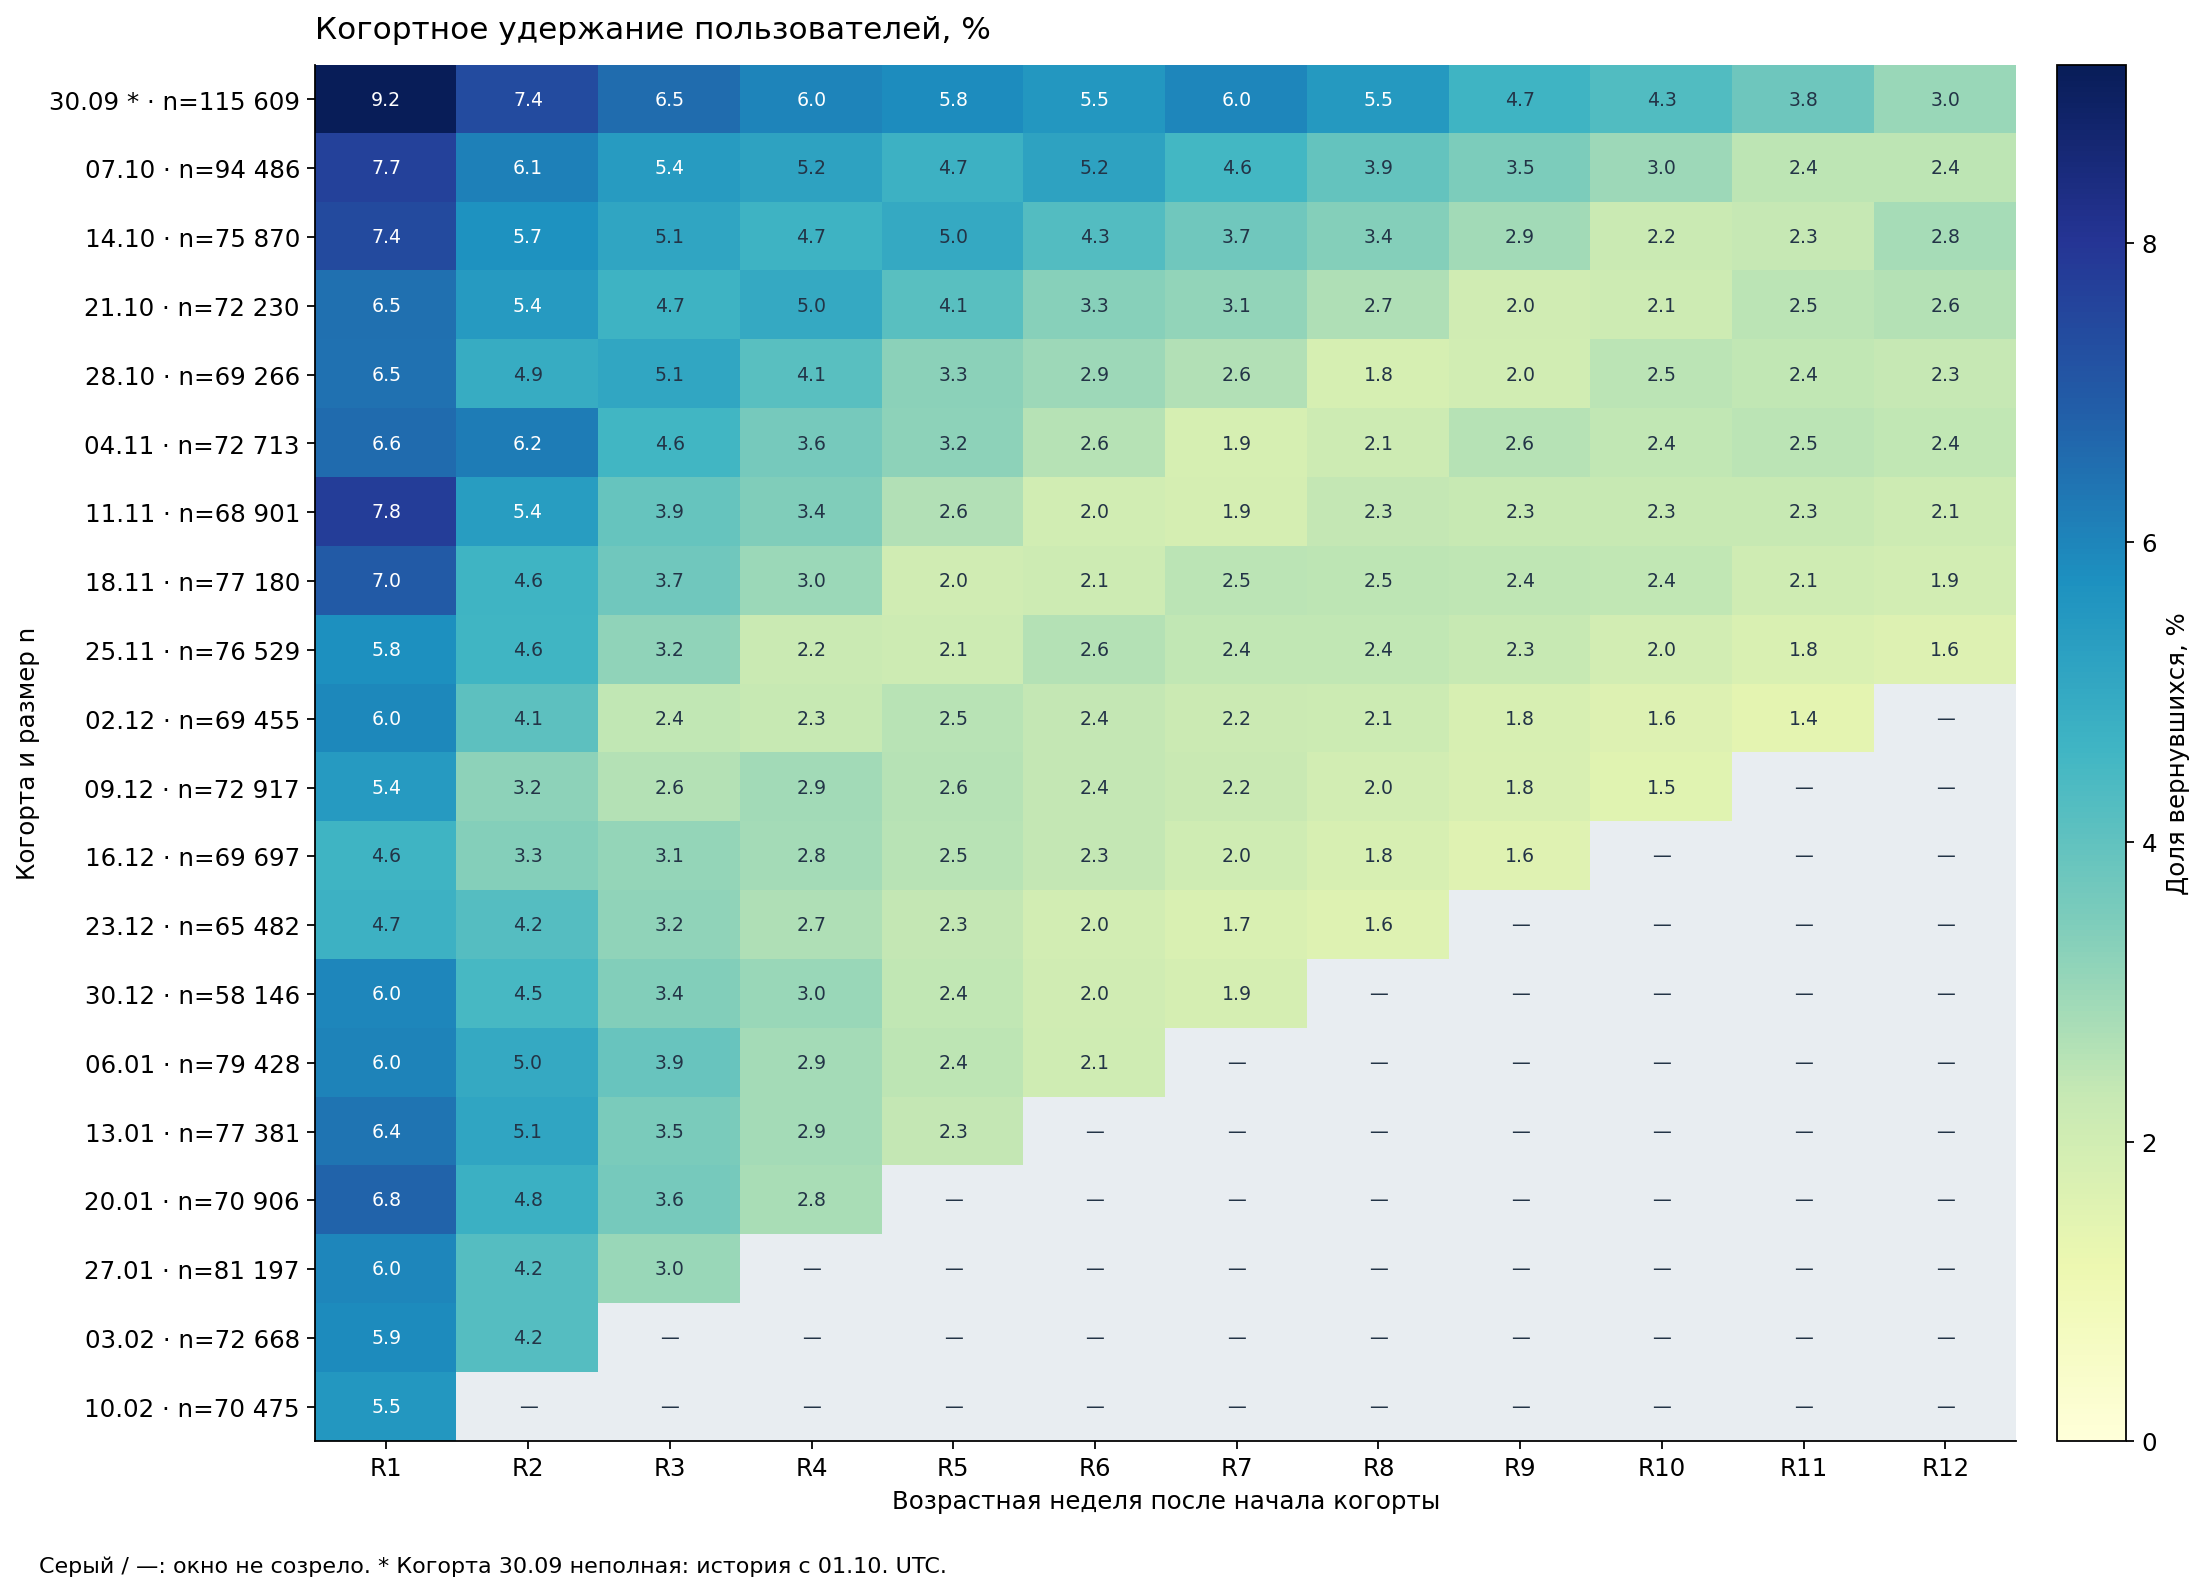

In [10]:
con.execute('''CREATE TABLE cohort_sizes AS SELECT cohort_week,count(*) AS cohort_n,
 min(first_day) AS min_first_day,max(first_day) AS max_first_day FROM users GROUP BY cohort_week''')
# Для зрелости берём воскресенье — последний возможный день первого события.
con.execute(f'''
CREATE TABLE cohort_retention AS
WITH activity AS (
 SELECT cohort_week, floor(age_day/7)::INTEGER AS age_week,count(DISTINCT user_id) AS active_n
 FROM user_day_age GROUP BY cohort_week,age_week
)
SELECT c.cohort_week,c.cohort_n,c.min_first_day,c.max_first_day,k.range::INTEGER AS age_week,
 coalesce(a.active_n,0) AS observed_active_n,
 (c.cohort_week+6+((k.range+1)*7)::INTEGER <= DATE '{T_END}') AS mature,
 CASE WHEN c.cohort_week+6+((k.range+1)*7)::INTEGER <= DATE '{T_END}' THEN coalesce(a.active_n,0)*1.0/c.cohort_n END AS retention
FROM cohort_sizes c CROSS JOIN range(0,22) k
LEFT JOIN activity a ON a.cohort_week=c.cohort_week AND a.age_week=k.range
''')
retention = sql('SELECT * FROM cohort_retention ORDER BY cohort_week,age_week')
check('Незрелые retention отсутствуют, не равны нулю', retention.loc[~retention['mature'],'retention'].isna().all())
check('Числитель не больше знаменателя', (retention.observed_active_n<=retention.cohort_n).all())
check('Полная когорта в каждом зрелом окне', all(r.max_first_day.date()+pd.Timedelta(days=(r.age_week+1)*7) <= T_END for r in retention[retention.mature].itertuples()))
retention.to_csv(ROOT/'outputs/tables/retention_full.csv',index=False,encoding='utf-8-sig')

ret_pivot = retention.pivot(index='cohort_week',columns='age_week',values='retention')
sizes = sql('SELECT * FROM cohort_sizes ORDER BY cohort_week').set_index('cohort_week')
ret_summary = sizes[['cohort_n']].rename(columns={'cohort_n':'Размер когорты'}).copy()
for k in [1,2,4,8,12,16,20]:
    ret_summary[f'R{k}, %'] = ret_pivot[k]*100
ret_summary.index = ret_summary.index.strftime('%d.%m.%Y')
ret_summary.index.name = 'Неделя первого появления'
show(ret_summary.reset_index(), 'retention_summary')  # Полная таблица в приложении.

plot = ret_pivot.loc[:,1:12]*100
plot = plot.loc[plot.notna().any(axis=1)]  # Только рисунок: полностью незрелые строки остаются в таблицах.
labels = [d.strftime('%d.%m') + (' *' if d.date()<T_START else '') + f' · n={fmt(int(sizes.loc[d,"cohort_n"]))}' for d in plot.index]
fig,ax = plt.subplots(figsize=(15,10))
cmap = plt.get_cmap('YlGnBu').copy()
cmap.set_bad('#e8edf1')
vmax = max(5.0,float(np.nanmax(plot.to_numpy())))
im = ax.imshow(np.ma.masked_invalid(plot.to_numpy()),aspect='auto',cmap=cmap,vmin=0,vmax=vmax)
ax.set_xticks(range(12),[f'R{k}' for k in range(1,13)])
ax.set_yticks(range(len(plot)),labels)
for i in range(len(plot)):
    for j in range(12):
        v=plot.iloc[i,j]
        ax.text(j,i,'—' if pd.isna(v) else f'{v:.1f}',ha='center',va='center',fontsize=8.5,color='white' if pd.notna(v) and v>vmax*.58 else '#233447')
ax.set_title('Когортное удержание пользователей, %',loc='left',pad=12)
ax.set_xlabel('Возрастная неделя после начала когорты')
ax.set_ylabel('Когорта и размер n')
fig.colorbar(im,ax=ax,pad=.02,label='Доля вернувшихся, %')
fig.text(.02,.01,'Серый / —: окно не созрело. * Когорта 30.09 неполная: история с 01.10. UTC.',fontsize=10)
fig.tight_layout(rect=[0,.03,1,1])
savefig(fig,'retention_heatmap')

In [11]:
con.execute(f'''
CREATE TABLE user_horizons AS
SELECT u.user_id,u.cohort_week,u.first_day,
 coalesce(bool_or(d.has_purchase) FILTER(WHERE d.age_day BETWEEN 0 AND 6),false) AS converted7,
 coalesce(bool_or(true) FILTER(WHERE d.age_day BETWEEN 28 AND 34),false) AS retained4,
 coalesce(bool_or(d.has_purchase) FILTER(WHERE d.age_day BETWEEN 0 AND 29),false) AS buyer30,
 coalesce(bool_or(d.has_purchase) FILTER(WHERE d.age_day BETWEEN 7 AND 34),false) AS repeat7_34,
 coalesce(bool_or(d.has_purchase) FILTER(WHERE d.age_day BETWEEN 7 AND 96),false) AS purchased7_96,
 coalesce(sum(d.value_raw) FILTER(WHERE d.age_day BETWEEN 0 AND 29),0) AS value30_raw,
 coalesce(sum(d.value_nonnegative) FILTER(WHERE d.age_day BETWEEN 0 AND 29),0) AS value30,
 coalesce(sum(d.value_capped) FILTER(WHERE d.age_day BETWEEN 0 AND 29),0) AS value30_capped
FROM users u JOIN user_day_age d USING(user_id,cohort_week,first_day)
GROUP BY u.user_id,u.cohort_week,u.first_day
''')
check('Горизонты: ровно одна строка на пользователя', scalar('SELECT count(*) FROM user_horizons') == scalar('SELECT count(*) FROM users') == scalar('SELECT count(DISTINCT user_id) FROM user_horizons'))
con.execute(f'''
CREATE TABLE cohort_metrics AS
SELECT cohort_week,count(*) AS cohort_n,
 cohort_week>=DATE '{T_START}' AND cohort_week+7<=DATE '{T_END}' AS full_calendar,
 cohort_week+13<=DATE '{T_END}' AS mature7,
 cohort_week+36<=DATE '{T_END}' AS mature30,
 cohort_week+41<=DATE '{T_END}' AS mature35,
 cohort_week+103<=DATE '{T_END}' AS mature96,
 sum(converted7::INTEGER) AS converted7_n,sum(retained4::INTEGER) AS retained4_n,
 sum(buyer30::INTEGER) AS buyer30_n,
 CASE WHEN cohort_week+13<=DATE '{T_END}' THEN avg(converted7::INTEGER) END AS cr7,
 CASE WHEN cohort_week+41<=DATE '{T_END}' THEN avg(retained4::INTEGER) END AS r4,
 CASE WHEN cohort_week+36<=DATE '{T_END}' THEN sum(value30)/count(*) END AS v30,
 CASE WHEN cohort_week+36<=DATE '{T_END}' THEN sum(value30_raw)/count(*) END AS v30_raw,
 CASE WHEN cohort_week+36<=DATE '{T_END}' THEN sum(value30_capped)/count(*) END AS v30_capped
FROM user_horizons GROUP BY cohort_week
''')


#### Сводка по когортам

In [12]:
cm = sql('SELECT * FROM cohort_metrics ORDER BY cohort_week')
r4_check = retention[retention.age_week==4].merge(cm[['cohort_week','r4']],on='cohort_week',validate='one_to_one')
check('Два способа R4 совпали', np.allclose(r4_check.retention,r4_check.r4,equal_nan=True))
check('CR7 в [0,1]', cm.cr7.dropna().between(0,1).all())
check('Незрелые V30 пустые', cm.loc[~cm.mature30,'v30'].isna().all())
cm.to_csv(ROOT/'outputs/tables/cohort_metrics_full.csv',index=False,encoding='utf-8-sig')

def wilson(successes,n):
    z=1.95996398454
    p=successes/n
    center=(p+z*z/(2*n))/(1+z*z/n)
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return center-half,center+half

aggregate=[]
for name,col,num,mature in [('Конверсия в покупку за первые 7 дней (CR7)','cr7','converted7_n','mature7'),('Удержание на четвёртой неделе (R4)','r4','retained4_n','mature35')]:
    eligible=cm[cm.full_calendar & cm[mature]]
    den=int(eligible.cohort_n.sum()); n=int(eligible[num].sum()); lo,hi=wilson(n,den)
    aggregate.append({'Метрика':name,'Зрелых полных когорт':len(eligible),'Пользователей':den,'Числитель':n,'Значение, %':n/den*100,'Нижняя 95%, %':lo*100,'Верхняя 95%, %':hi*100})
aggregate=pd.DataFrame(aggregate)
show(aggregate,'cohort_aggregate')
APPENDIX.append(('Пояснение к диагностике',Markdown('Интервалы Уилсона описывают неопределённость доли при условной независимости идентификаторов. Они не учитывают ошибки трекинга, неполную историю и календарное смешение; причинной интерпретации не имеют. Взвешивание выполнено числом пользователей, а не средним от процентов когорт.')))


check('Зрелые окна метрик полностью наблюдаются', all(
    row.max_first_day.date() + pd.Timedelta(days=days) <= T_END
    for days, flag in [(7, 'mature7'), (30, 'mature30'), (35, 'mature35'), (97, 'mature96')]
    for row in cm[cm[flag]].merge(sizes[['max_first_day']], on='cohort_week').itertuples()))


#### Результаты и график CR7

,Метрика,Окно,Зрелых полных когорт,Числитель,Знаменатель,"Доля, %"
0,Прокси: покупка в дни 7–96,≥1 purchase в возрасте 7–96 / вся когорта,7,20981,530646,3.9539


**Предварительный индикатор:** в историческом прокси purchase в дни 7–96 зарегистрирован у 20 981 из 530 646 впервые наблюдаемых пользователей (3,95%; 7 полных зрелых когорт). В тесте знаменатель — все рандомизированные, а не только ранние покупатели. Историческая выборка не содержит рандомизации, поэтому это не оценка эффекта и не доказанный guardrail.

**Покупочная частота как ориентир окна:** среди ранних покупателей, у которых в доступной истории есть purchase на более позднюю календарную дату, интервал до первого такого дня: медиана 25 дн., P75 48 дн., P90 76 дн. Это описание только наблюдавших повтор и оно ограничено концом истории; покупки внутри одного дня/заказа не различимы.

**Возврат:** R4 различается между зрелыми когортами от 2,20% до 5,19%. Это основание сравнить календарь и товарный интерес; причина различий не установлена. Далее — сопоставимые когорты и будущий тест, а не вывод о деградации продукта.

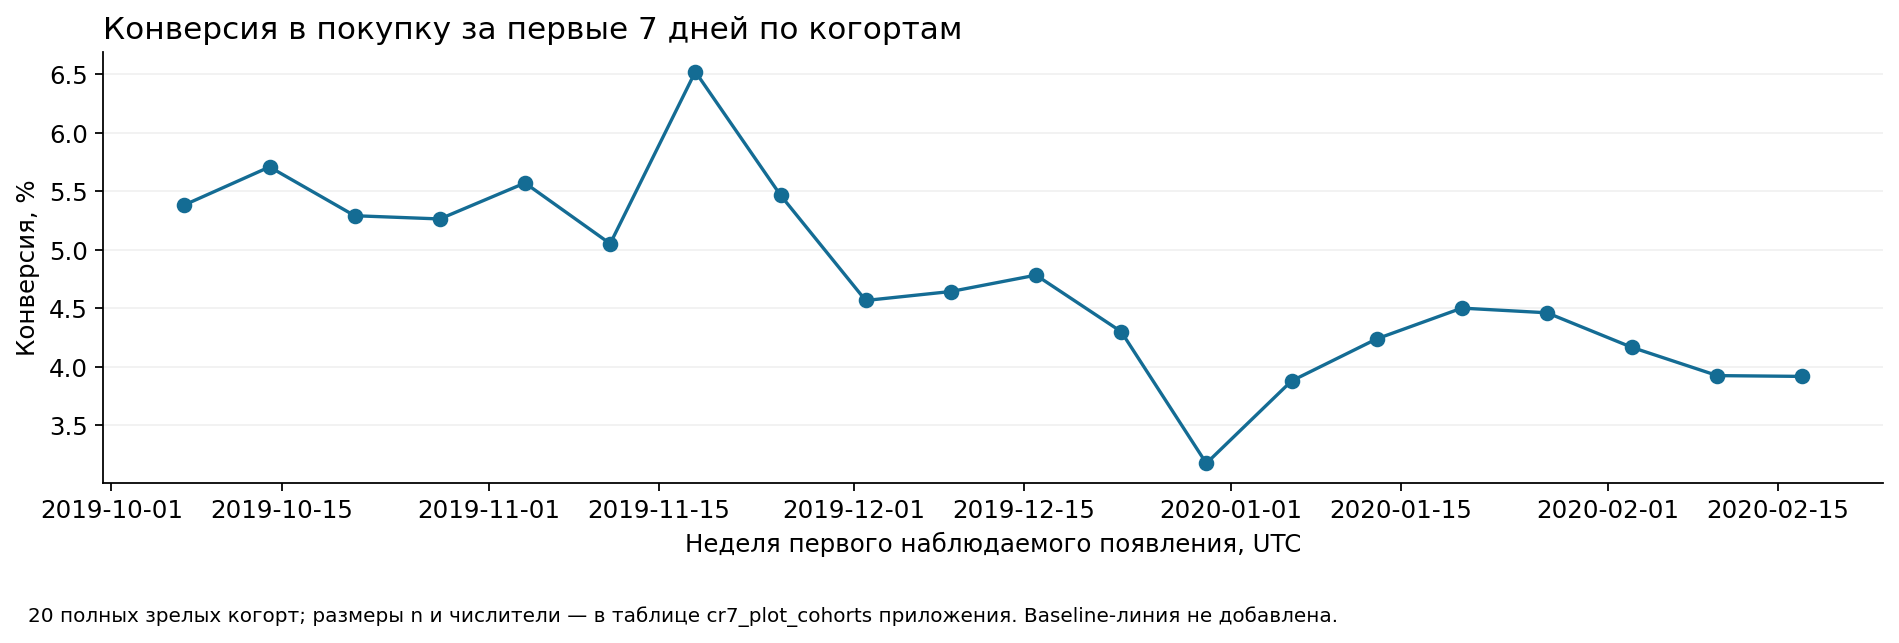

**Конверсия за первые 7 дней:** различия зрелых когорт показывают неоднородность ранней покупки. Это помогает выбрать сопоставимые календарные группы для проверки; эффект информации о доставке этим графиком не установлен. Размеры когорт — в приложении.

In [13]:
first_cohort=cm.iloc[0]
eligible_r4=cm[cm.full_calendar & cm.mature35]
minr=eligible_r4.loc[eligible_r4.r4.idxmin()]
maxr=eligible_r4.loc[eligible_r4.r4.idxmax()]
APPENDIX.append(('Пояснение к диагностике',Markdown(f'''**Что видно по возврату.** Для полных зрелых календарных когорт сводный `R4` равен **{fmt(aggregate.loc[aggregate.Метрика=='Удержание на четвёртой неделе (R4)','Значение, %'].iloc[0],2)}%**, `CR7` — **{fmt(aggregate.loc[aggregate.Метрика=='Конверсия в покупку за первые 7 дней (CR7)','Значение, %'].iloc[0],2)}%**; набор зрелых когорт у этих показателей различается. `R4` отдельных полных когорт лежит от **{pct(minr.r4)}** ({minr.cohort_week:%d.%m}) до **{pct(maxr.r4)}** ({maxr.cohort_week:%d.%m}). Это наблюдаемая неоднородность, а не результат изменения продукта. Начальная неполная когорта имеет {fmt(int(first_cohort.cohort_n))} пользователей и `R4` {pct(first_cohort.r4)}; она вынесена из сводного baseline, поскольку начало истории особенно ограничивает её интерпретацию. Следующее решение — исследовать различия зрелых когорт и товарного интереса, не объявляя отсутствие возврата доказанным окончательным уходом.''')))
risk=sql("""SELECT count(*) AS denominator,count(*) FILTER(WHERE purchased7_96) AS numerator,
 count(DISTINCT cohort_week) AS mature_cohorts
FROM user_horizons JOIN cohort_metrics USING(cohort_week) WHERE full_calendar AND mature96""").iloc[0]
risk_itt_proxy=float(risk.numerator/risk.denominator)
check('Исторический прокси риска: числитель в знаменателе',0<=risk.numerator<=risk.denominator)
show(pd.DataFrame([{'Метрика':'Прокси: покупка в дни 7–96','Окно':'≥1 purchase в возрасте 7–96 / вся когорта','Зрелых полных когорт':int(risk.mature_cohorts),'Числитель':int(risk.numerator),'Знаменатель':int(risk.denominator),'Доля, %':100*risk_itt_proxy}]),'risk_summary')
repeat_days=sql("""WITH first_purchase AS (
 SELECT user_id,min(event_day) AS first_purchase_day
 FROM events WHERE event_type='purchase' GROUP BY 1),
 repeaters AS (
 SELECT f.user_id,f.first_purchase_day,
  min(e.event_day) FILTER(WHERE e.event_day>f.first_purchase_day) AS next_purchase_day
 FROM first_purchase f LEFT JOIN events e ON e.user_id=f.user_id AND e.event_type='purchase'
  AND e.event_day>f.first_purchase_day GROUP BY 1,2)
SELECT count(*) FILTER(WHERE next_purchase_day IS NOT NULL) AS users_with_later_day_purchase,
 quantile_cont(date_diff('day',first_purchase_day,next_purchase_day),0.5) AS median_days,
 quantile_cont(date_diff('day',first_purchase_day,next_purchase_day),0.75) AS p75_days,
 quantile_cont(date_diff('day',first_purchase_day,next_purchase_day),0.9) AS p90_days
FROM repeaters WHERE next_purchase_day IS NOT NULL""").iloc[0]
display(Markdown(f"**Предварительный индикатор:** в историческом прокси purchase в дни 7–96 зарегистрирован у {fmt(int(risk.numerator))} из {fmt(int(risk.denominator))} впервые наблюдаемых пользователей ({pct(risk_itt_proxy)}; {int(risk.mature_cohorts)} полных зрелых когорт). В тесте знаменатель — все рандомизированные, а не только ранние покупатели. Историческая выборка не содержит рандомизации, поэтому это не оценка эффекта и не доказанный guardrail."))
display(Markdown(f"**Покупочная частота как ориентир окна:** среди ранних покупателей, у которых в доступной истории есть purchase на более позднюю календарную дату, интервал до первого такого дня: медиана {int(repeat_days.median_days)} дн., P75 {int(repeat_days.p75_days)} дн., P90 {int(repeat_days.p90_days)} дн. Это описание только наблюдавших повтор и оно ограничено концом истории; покупки внутри одного дня/заказа не различимы."))
display(Markdown(f"**Возврат:** R4 различается между зрелыми когортами от {pct(minr.r4)} до {pct(maxr.r4)}. Это основание сравнить календарь и товарный интерес; причина различий не установлена. Далее — сопоставимые когорты и будущий тест, а не вывод о деградации продукта."))
cr7_plot=cm.loc[cm.full_calendar & cm.mature7,['cohort_week','cohort_n','converted7_n','cr7']].copy()
show(cr7_plot,'cr7_plot_cohorts')
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(cr7_plot.cohort_week,100*cr7_plot.cr7,marker='o',color='#146c94')
ax.set_title('Конверсия в покупку за первые 7 дней по когортам',loc='left')
ax.set_ylabel('Конверсия, %');ax.set_xlabel('Неделя первого наблюдаемого появления, UTC')
ax.grid(axis='y',alpha=.18)
fig.text(.02,.01,'20 полных зрелых когорт; размеры n и числители — в таблице cr7_plot_cohorts приложения. Baseline-линия не добавлена.',fontsize=9)
fig.tight_layout(rect=[0,.07,1,1]);savefig(fig,'cr7_cohorts')
display(Markdown('**Конверсия за первые 7 дней:** различия зрелых когорт показывают неоднородность ранней покупки. Это помогает выбрать сопоставимые календарные группы для проверки; эффект информации о доставке этим графиком не установлен. Размеры когорт — в приложении.'))


### 6.2. Покупатели за неделю

График показывает WBU и активных пользователей за неделю (WAU) за 20 полных календарных недель. Крайние неполные недели исключены.

In [14]:
con.execute(f'''
CREATE TABLE user_week_flags AS
SELECT user_id,date_trunc('week',event_day)::DATE AS week,
 bool_or(has_purchase) AS has_purchase,bool_or(has_cart) AS has_cart,bool_or(has_remove) AS has_remove
FROM user_days GROUP BY user_id,week
''')
con.execute(f'''
CREATE TABLE weekly AS
SELECT week,count(*) AS wau,count(*) FILTER(WHERE has_purchase) AS wbu,
 count(*) FILTER(WHERE has_cart) AS cart_users,
 count(*) FILTER(WHERE has_cart AND has_remove) AS edited_users,
 count(*) FILTER(WHERE has_cart AND has_remove)*1.0/nullif(count(*) FILTER(WHERE has_cart),0) AS bedit,
 week>=DATE '{T_START}' AND week+7<=DATE '{T_END}' AS full_week
FROM user_week_flags GROUP BY week
''')
weekly=sql('SELECT * FROM weekly ORDER BY week')
check('WBU не выше WAU', (weekly.wbu<=weekly.wau).all())
weekly.to_csv(ROOT/'outputs/tables/weekly_metrics_full.csv',index=False,encoding='utf-8-sig')
complete_weeks=weekly[weekly.full_week].copy()
out=complete_weeks[['week','wau','wbu','cart_users','edited_users','bedit']].rename(columns={'week':'Неделя UTC','wau':'Активных','wbu':'Покупатели за неделю','cart_users':'Пользователей с cart','edited_users':'Пользователь-недели с редактированием корзины','bedit':'Редактирование корзины, %'})
out['Редактирование корзины, %']=out['Редактирование корзины, %']*100
show(out,'weekly_metrics')



#### Недельный ряд и диагностика

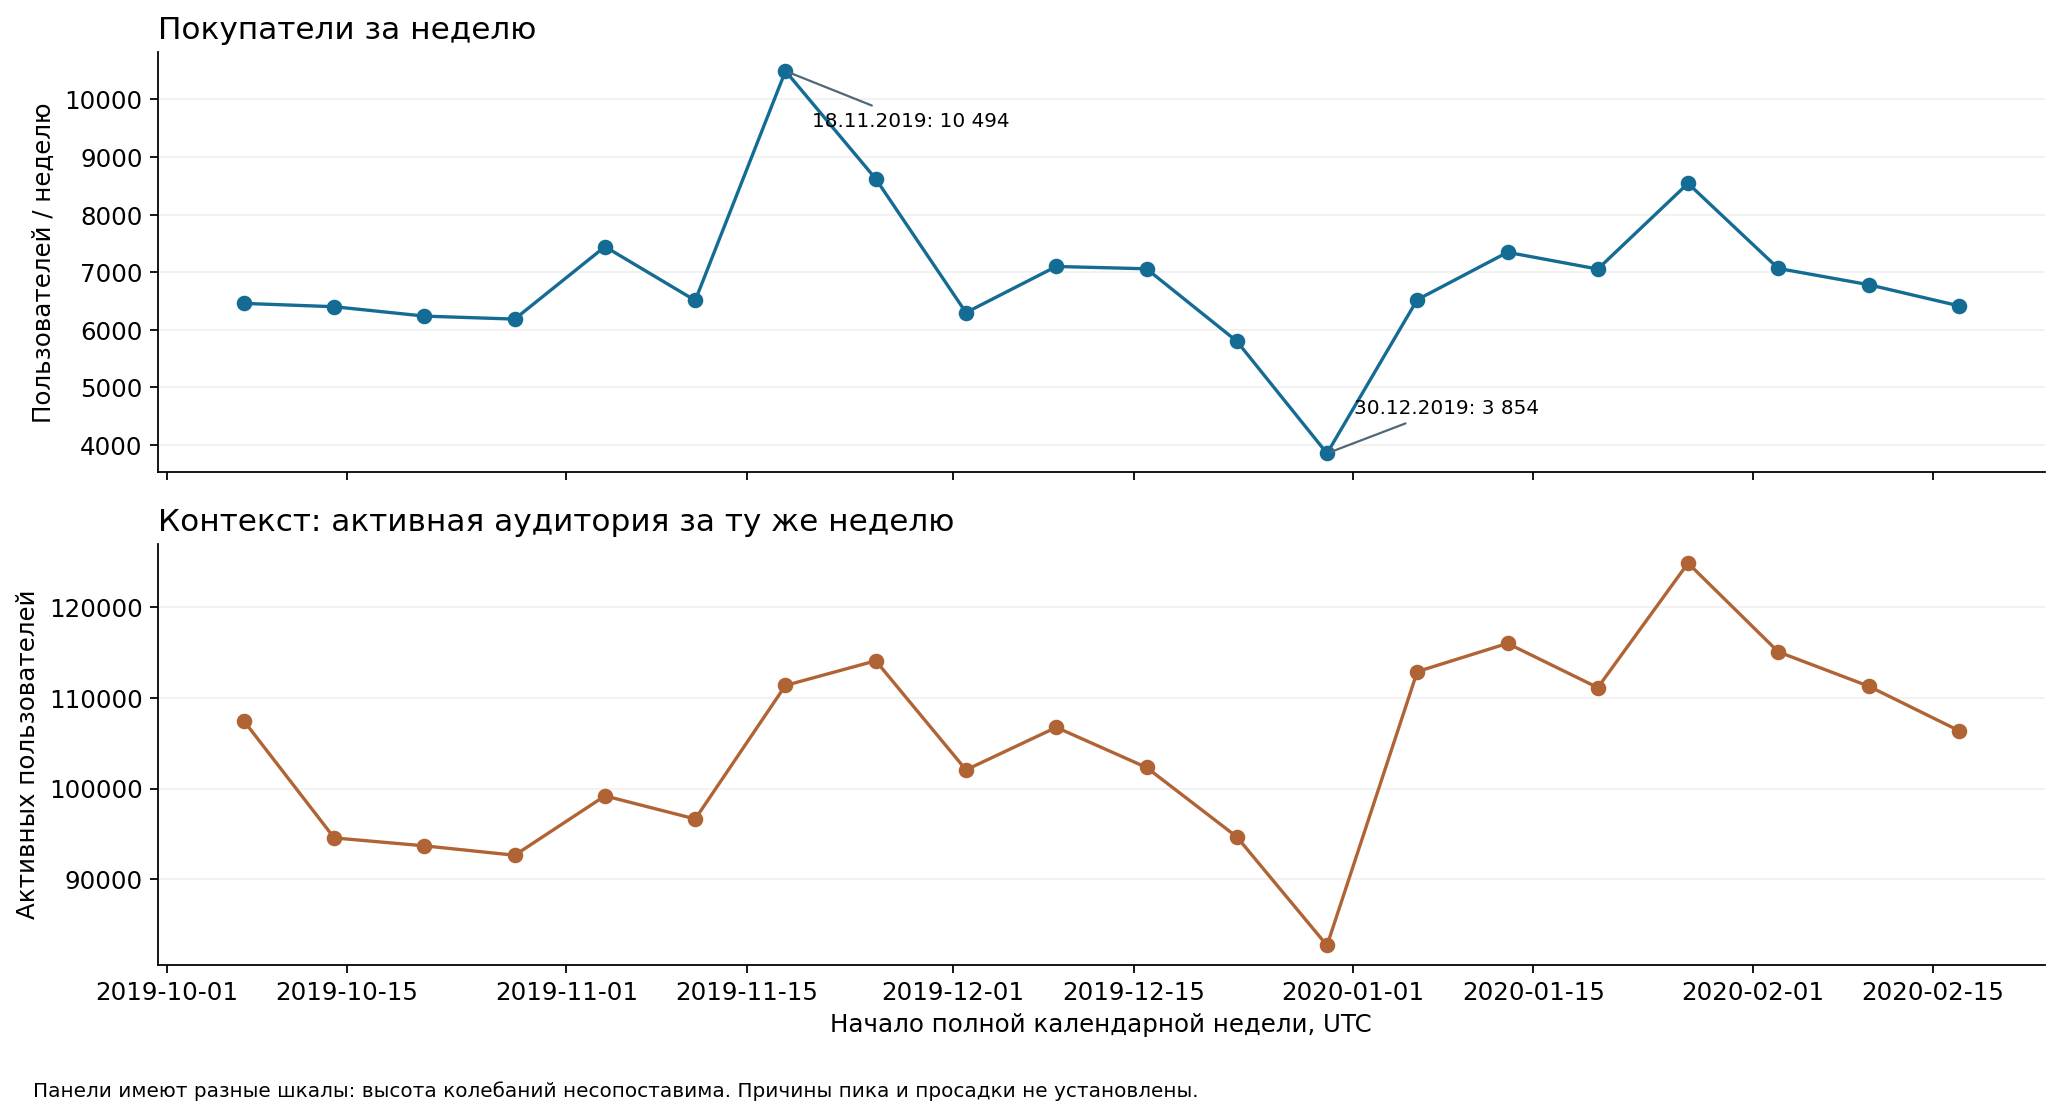

In [15]:
risk_alternatives=sql(f'''
SELECT 'Основной: пользователь-неделя' AS variant,sum(edited_users) AS numerator,sum(cart_users) AS denominator,
 sum(edited_users)*1.0/sum(cart_users) AS rate FROM weekly WHERE full_week
UNION ALL SELECT 'Техническая сессия: все длительности',
 count(*) FILTER(WHERE has_cart AND has_remove),count(*) FILTER(WHERE has_cart),
 count(*) FILTER(WHERE has_cart AND has_remove)*1.0/nullif(count(*) FILTER(WHERE has_cart),0)
FROM sessions WHERE date_trunc('week',first_day)::DATE>=DATE '{T_START}' AND date_trunc('week',first_day)::DATE+7<=DATE '{T_END}'
UNION ALL SELECT 'Техническая сессия: размах не более 24 часов',
 count(*) FILTER(WHERE has_cart AND has_remove),count(*) FILTER(WHERE has_cart),
 count(*) FILTER(WHERE has_cart AND has_remove)*1.0/nullif(count(*) FILTER(WHERE has_cart),0)
FROM sessions WHERE date_trunc('week',first_day)::DATE>=DATE '{T_START}' AND date_trunc('week',first_day)::DATE+7<=DATE '{T_END}'
 AND date_diff('second',first_time,last_time)<=86400
''')
risk_alternatives['rate']=risk_alternatives['rate']*100
risk_alternatives=risk_alternatives.rename(columns={'variant':'Единица и окно','numerator':'Числитель','denominator':'Знаменатель','rate':'Редактирование корзины, %'})
show(risk_alternatives,'basket_risk_definitions')
APPENDIX.append(('Пояснение к диагностике',Markdown('У сессионных вариантов другой знаменатель; различия не являются изменением поведения или эффектом очистки. Основное пользовательское недельное окно устраняет зависимость метрики от необычной длительности технической сессии.')))

fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
axes[0].plot(complete_weeks.week,complete_weeks.wbu,marker='o',color='#146c94',label='Покупатели за неделю')
axes[0].set_ylabel('Пользователей / неделю')
axes[0].set_title('Покупатели за неделю',loc='left')
axes[0].grid(axis='y',alpha=.18)
axes[1].plot(complete_weeks.week,complete_weeks.wau,marker='o',color='#b06435')
axes[1].set_ylabel('Активных пользователей')
axes[1].set_title('Контекст: активная аудитория за ту же неделю',loc='left')
axes[1].set_xlabel('Начало полной календарной недели, UTC')
axes[1].grid(axis='y',alpha=.18)
hi=complete_weeks.loc[complete_weeks.wbu.idxmax()];lo=complete_weeks.loc[complete_weeks.wbu.idxmin()]
axes[0].annotate(f'{hi.week:%d.%m.%Y}: {int(hi.wbu):,}'.replace(',',' '),xy=(hi.week,hi.wbu),xytext=(12,-25),textcoords='offset points',arrowprops={'arrowstyle':'-','color':'#516776'},fontsize=9)
axes[0].annotate(f'{lo.week:%d.%m.%Y}: {int(lo.wbu):,}'.replace(',',' '),xy=(lo.week,lo.wbu),xytext=(12,18),textcoords='offset points',arrowprops={'arrowstyle':'-','color':'#516776'},fontsize=9)
fig.text(.02,.01,'Панели имеют разные шкалы: высота колебаний несопоставима. Причины пика и просадки не установлены.',fontsize=9)
fig.tight_layout(rect=[0,.04,1,1])
savefig(fig,'weekly_northstar_risk')

basket_context=sql(f"""
SELECT CASE WHEN has_remove THEN 'С cart и удалением' ELSE 'С cart, без удаления' END AS "Группа пользователь-недель",
 count(*) AS "Наблюдений", count(*) FILTER(WHERE has_purchase) AS "С purchase",
 100.0*count(*) FILTER(WHERE has_purchase)/count(*) AS "С purchase, %"
FROM user_week_flags WHERE has_cart AND week>=DATE '{T_START}' AND week+7<=DATE '{T_END}'
GROUP BY has_remove ORDER BY has_remove DESC
""")
show(basket_context, 'basket_purchase_context')
without_first=complete_weeks.iloc[1:]
bedit_without_first=float(without_first.edited_users.sum()/without_first.cart_users.sum())
show(pd.DataFrame({'Выборка':['Все 20 полных недель','Без первой полной недели: только чувствительность'],
                  'Редактирование корзины, %':[100*complete_weeks.edited_users.sum()/complete_weeks.cart_users.sum(),100*bedit_without_first]}), 'bedit_first_week_sensitivity')
APPENDIX.append(('Пояснение к диагностике',Markdown(f"**Редактирование корзины (BEdit), только диагностика.** В тех же пользователь-неделях с cart доля с purchase равна {fmt(basket_context.iloc[0]['С purchase, %'],2)}% у редактирующих и {fmt(basket_context.iloc[1]['С purchase, %'],2)}% у остальных. Группы различаются по вовлечённости; обратная причинность и состав аудитории не контролируются. По этим долям нельзя установить вред удаления или эффект интерфейса. Без первой полной недели общий BEdit = {pct(bedit_without_first)}; неделя не удаляется из основного baseline. Следующая проверка — стабильность регистрации remove_from_cart и пути пользователей в начале октября, затем сравнение сопоставимых групп. Число правок корзины не следует снижать само по себе.")))



#### Неактивность

In [16]:
churn=[]
for gap in [14,30,45]:
    eligible=int(scalar(f"SELECT count(*) FROM users WHERE first_day<=DATE '{T_END}'-{gap}"))
    inactive=int(scalar(f"SELECT count(*) FROM users WHERE first_day<=DATE '{T_END}'-{gap} AND last_day<DATE '{T_END}'-{gap}"))
    churn.append({'Окно без событий, дней':gap,'Достаточно наблюдались':eligible,'Неактивных':inactive,'Доля, %':inactive/eligible*100})
churn=pd.DataFrame(churn)
show(churn,'inactivity_sensitivity')
ch30=churn[churn['Окно без событий, дней']==30].iloc[0]
peak=complete_weeks.loc[complete_weeks.wbu.idxmax()]
APPENDIX.append(('Пояснение к диагностике',Markdown(f'''**Интерпретация.** Максимум WBU среди полных недель — **{fmt(int(peak.wbu))}** на неделе {peak.week:%d.%m.%Y}. Причина пика из логов не устанавливается: нельзя автоматически приписывать его рекламе или акции. В среднем по полным неделям WBU = **{fmt(complete_weeks.wbu.mean(),1)}**; суммарная доля пользователь-недель с добавлением и удалением среди пользователь-недель с добавлением — **{pct(complete_weeks.edited_users.sum()/complete_weeks.cart_users.sum())}**. Это редактирование, а не доля отмен. На 01.03.2020 по правилу 30 дней наблюдаемо неактивны **{fmt(int(ch30['Неактивных']))}** из **{fmt(int(ch30['Достаточно наблюдались']))}** достаточно давно появившихся пользователей (**{fmt(ch30['Доля, %'],2)}%**). Знаменатель исключает пользователей с недостаточной давностью появления. Доля рассчитана на явно заданной популяции. Варианты 14 и 45 дней показывают зависимость от определения, а не три разных оценки «истинного» ухода.''')))
display(Markdown(f"**Наблюдение:** средний WBU — {fmt(complete_weeks.wbu.mean(),1)}, пик {fmt(int(peak.wbu))} на неделе {peak.week:%d.%m.%Y}. Сравнение с активной аудиторией помогает отличать масштаб от покупательной активности; дальше проверить календарный состав и логирование, не приписывая пик акции или рекламе."))

**Наблюдение:** средний WBU — 6 910,2, пик 10 494 на неделе 18.11.2019. Сравнение с активной аудиторией помогает отличать масштаб от покупательной активности; дальше проверить календарный состав и логирование, не приписывая пик акции или рекламе.

### 6.3. Стоимость событий за первые 30 дней (V30)

V30 — сумма неотрицательного `price` у `purchase` в дни 0–29, делённая на всех пользователей зрелой когорты. Это стоимость событий, не подтверждённые оплаты, выручка или прибыль. Чувствительность и когортный график приведены в приложении.

In [17]:
con.execute('''CREATE TABLE duplicate_money_days AS
SELECT try_cast(user_id AS BIGINT) AS user_id,try_strptime(event_time, '%Y-%m-%d %H:%M:%S UTC')::DATE AS event_day,
 sum((n-1)*try_cast(price AS DECIMAL(18,2))) AS duplicate_value
FROM duplicate_groups WHERE event_type='purchase' AND try_cast(price AS DECIMAL(18,2))>=0 GROUP BY 1,2''')
con.execute('''CREATE TABLE duplicate_money30 AS SELECT d.user_id,sum(d.duplicate_value) AS duplicate_value30
FROM duplicate_money_days d JOIN users u USING(user_id)
WHERE date_diff('day',u.first_day,d.event_day) BETWEEN 0 AND 29 GROUP BY d.user_id''')
con.execute('''CREATE TABLE user_value_sensitivity AS SELECT h.*,coalesce(d.duplicate_value30,0) AS duplicate_value30,
 h.value30-coalesce(d.duplicate_value30,0) AS value30_one_copy,
 s.user_id IS NOT NULL AS suspicious
FROM user_horizons h LEFT JOIN duplicate_money30 d USING(user_id) LEFT JOIN suspicious_users s USING(user_id)''')
check('Денежные соединения не размножили пользователей',scalar('SELECT count(*) FROM user_value_sensitivity') == scalar('SELECT count(*) FROM users'))

money_global=sql(f'''
SELECT 'Исходные цены, все purchase' AS variant,sum(price)::DOUBLE AS value FROM events WHERE event_type='purchase'
UNION ALL SELECT 'Основной: price ≥ 0',sum(price)::DOUBLE FROM events WHERE event_type='purchase' AND price>=0
UNION ALL SELECT 'Одна копия совпадения, price ≥ 0',
 (SELECT sum(price) FROM events WHERE event_type='purchase' AND price>=0)-(SELECT sum(duplicate_value) FROM duplicate_money_days)
UNION ALL SELECT 'Ограничение P99,9, price ≥ 0',sum(least(price,{CAP}))::DOUBLE FROM events WHERE event_type='purchase' AND price>=0
''')
money_global=money_global.rename(columns={'variant':'Вариант','value':'Стоимость событий за все 5 месяцев'})
show(money_global,'money_global_sensitivity')



#### Когортный V30

In [18]:
money_cohorts=sql(f'''
SELECT v.cohort_week,count(*) AS cohort_n,sum(buyer30::INTEGER) AS buyers30,
 sum(value30)::DOUBLE AS total30,avg(value30)::DOUBLE AS v30,
 avg(value30_raw)::DOUBLE AS v30_raw,avg(value30_one_copy)::DOUBLE AS v30_one_copy,
 avg(value30_capped)::DOUBLE AS v30_capped,
 quantile_cont(value30,0.5)::DOUBLE AS median_user30,quantile_cont(value30,0.99)::DOUBLE AS p99_user30
FROM user_value_sensitivity v JOIN cohort_metrics c USING(cohort_week)
WHERE c.mature30 GROUP BY v.cohort_week ORDER BY v.cohort_week
''')
money_cohorts.to_csv(ROOT/'outputs/tables/money_cohorts_full.csv',index=False,encoding='utf-8-sig')
money_display=money_cohorts[['cohort_week','cohort_n','buyers30','v30','v30_raw','v30_one_copy','v30_capped']].rename(columns={'cohort_week':'Когорта UTC','cohort_n':'Пользователей','buyers30':'С purchase за 30 дней','v30':'V30 основной','v30_raw':'V30 исходный','v30_one_copy':'V30 одна копия','v30_capped':'V30 P99,9'})
show(money_display,'money_cohorts')

money_overall=sql('''SELECT count(*) AS users_n,sum(buyer30::INTEGER) AS buyers30,
 sum(value30)::DOUBLE AS sum30,avg(value30)::DOUBLE AS v30,
 avg(value30_raw)::DOUBLE AS raw,avg(value30_one_copy)::DOUBLE AS one_copy,
 avg(value30_capped)::DOUBLE AS capped,quantile_cont(value30,0.5)::DOUBLE AS median,
 quantile_cont(value30,0.9)::DOUBLE AS p90,quantile_cont(value30,0.99)::DOUBLE AS p99,
 max(value30)::DOUBLE AS max_value
FROM user_value_sensitivity JOIN cohort_metrics USING(cohort_week) WHERE full_calendar AND mature30''').iloc[0]
check('V30: пользовательская и когортная агрегации совпадают',np.isclose(money_overall.sum30,money_cohorts[money_cohorts.cohort_week.dt.date>=T_START].total30.sum()))



#### График и чувствительность

In [19]:
fig,ax=plt.subplots(figsize=(13,5))
full_money_plot=money_cohorts[money_cohorts.cohort_week.dt.date>=T_START]
ax.plot(full_money_plot.cohort_week,full_money_plot.v30,marker='o',label='Основной: полные когорты',color='#146c94')
initial_money=money_cohorts[money_cohorts.cohort_week.dt.date<T_START]
ax.scatter(initial_money.cohort_week,initial_money.v30,facecolors='none',edgecolors='#737373',s=70,label='Неполная начальная когорта')
ax.set_title('Стоимость покупочных событий\nза первые 30 дней на пользователя',loc='left')
ax.set_ylabel('Стоимость событий / пользователь, ден. ед.')
ax.set_xlabel('Начало когорты, UTC')
ax.legend(frameon=False)
ax.grid(axis='y',alpha=.18)
delta_one_copy=(money_overall.one_copy/money_overall.v30-1)*100
fig.text(.02,.01,f'Одна копия совпадений: общий V30 меняется на {fmt(delta_one_copy,3)}%. Полные варианты — в таблице чувствительности.',fontsize=9)
fig.tight_layout(rect=[0,.08,1,1])
savefig(fig,'value30_cohorts')

money_sensitivity=pd.DataFrame([
 {'Вариант':'Основной','V30':money_overall.v30},
 {'Вариант':'Исходные цены с отрицательными','V30':money_overall.raw},
 {'Вариант':'Одна копия полного совпадения','V30':money_overall.one_copy},
 {'Вариант':'Ограничение P99,9','V30':money_overall.capped}])
money_sensitivity['Изменение к основному, %']=(money_sensitivity.V30/money_overall.v30-1)*100
show(money_sensitivity,'value30_sensitivity')

APPENDIX.append(('Пояснение к диагностике',Markdown(f'''**Что измерено деньгами.** Для {fmt(int(money_overall.users_n))} пользователей полных зрелых когорт средний `V30` = **{fmt(money_overall.v30,4)}** денежных единиц на пользователя. Покупочное событие за 30 дней есть у **{pct(money_overall.buyers30/money_overall.users_n)}** пользователей; медиана пользовательской стоимости = **{fmt(money_overall['median'],2)}**, P99 = **{fmt(money_overall.p99,2)}**. Среднее не описывает типичного пользователя. Исходные отрицательные цены меняют среднее на **{fmt((money_overall.raw/money_overall.v30-1)*100,4)}%**, сценарий одной копии совпадения — на **{fmt((money_overall.one_copy/money_overall.v30-1)*100,2)}%**, ограничение P99,9 — на **{fmt((money_overall.capped/money_overall.v30-1)*100,2)}%**. В этих проверенных сценариях денежное среднее меняется умеренно; это не устраняет неопределённость оплаты, количества, возвратов и маржи. Совпадения во всём наборе не означают такой же процент искажения покупочной стоимости. Эти сценарии не затрагивают факт пользовательской активности и покупки.''')))
brief=pd.DataFrame([
 {'Метрика':'CR7','Окно':'0–6','Выборка':'20 полных зрелых когорт','Числитель / знаменатель':'69 818 / 1 462 284','Значение':'4,77%'},
 {'Метрика':'R4','Окно':'28–34','Выборка':'16 полных зрелых когорт','Числитель / знаменатель':'39 513 / 1 170 587','Значение':'3,38%'},
 {'Метрика':'V30','Окно':'0–29','Выборка':'16 полных зрелых когорт','Числитель / знаменатель':fmt(money_overall.sum30,2)+' / '+fmt(int(money_overall.users_n)),'Значение':fmt(money_overall.v30,4)+' ден. ед./польз.'},
 {'Метрика':'WBU','Окно':'Календарная неделя','Выборка':'20 полных недель','Числитель / знаменатель':'Уникальные с purchase, затем среднее недель','Значение':fmt(complete_weeks.wbu.mean(),1)}])
show(brief,'results_brief')
display(Markdown(f"**Стоимость событий:** V30 = {fmt(money_overall.v30,4)}, медиана пользователя — 0. Это основание учитывать непокупавших и чувствительность к крупным значениям; для бюджетного решения нужны условия следующего сценария, а для фактической экономики — оплаты и затраты."))

,Метрика,Окно,Выборка,Числитель / знаменатель,Значение
0,CR7,0–6,20 полных зрелых когорт,69 818 / 1 462 284,"4,77%"
1,R4,28–34,16 полных зрелых когорт,39 513 / 1 170 587,"3,38%"
2,V30,0–29,16 полных зрелых когорт,"3 080 390,48 / 1 170 587","2,6315 ден. ед./польз."
3,WBU,Календарная неделя,20 полных недель,"Уникальные с purchase, затем среднее недель","6 910,2"


**Стоимость событий:** V30 = 2,6315, медиана пользователя — 0. Это основание учитывать непокупавших и чувствительность к крупным значениям; для бюджетного решения нужны условия следующего сценария, а для фактической экономики — оплаты и затраты.

In [20]:
# Чувствительность к эвристике необычной активности: сравниваем внутри того же окна зрелости.
heuristic=[]
for label,field,condition in [('CR7','converted7','c.full_calendar AND c.mature7'),('R4','retained4','c.full_calendar AND c.mature35'),('V30','value30','c.full_calendar AND c.mature30')]:
    r=sql(f'''SELECT count(*) AS n,count(*) FILTER(WHERE suspicious) AS flagged,
    avg({field}::DOUBLE) AS main,avg({field}::DOUBLE) FILTER(WHERE NOT suspicious) AS without_flagged
    FROM user_value_sensitivity v JOIN cohort_metrics c USING(cohort_week) WHERE {condition}''').iloc[0]
    scale=100 if label!='V30' else 1
    heuristic.append({'Метрика':label,'Пользователей':int(r.n),'Помечено':int(r.flagged),'Основной':r.main*scale,'Без эвристической группы':r.without_flagged*scale,'Разница':(r.without_flagged-r.main)*scale,'Единица':'п.п. для разницы; % для уровней' if scale==100 else 'ден. ед./польз.'})
heuristic=pd.DataFrame(heuristic)
show(heuristic,'heuristic_sensitivity')
APPENDIX.append(('Пояснение к диагностике',Markdown('Эвристическая группа сохранена в основных результатах. Её исключение меняет и состав знаменателя, поэтому разница не доказывает наличие тестовых записей. Надёжного списка тестовых пользователей, ботов и служебных ID в наборе нет. Для полных совпадений пользовательские CR7, R4, WBU и BEdit, а также флаги событий технической сессии остаются неизменными: после оставления одной копии у каждого исходного события остаётся представитель с теми же пользователем, временем, типом и сессией.')))

<a id="economics"></a>
### 6.4. Сценарная экономика

Для первых наблюдаемых `user_id` из 16 полных зрелых когорт с G30 заданы два синтетических поля: условный канал и расходы на пользователя. Первый `user_id` — прокси привлечения.

Условные каналы, доли 50/30/20 и расходы 1/2/3 заданы как сценарные параметры: исходные данные не содержат каналов и расходов. Назначение фиксированное (seed 20261101, BLAKE2b от `user_id`) и независимо от поведения.

CAC — стоимость привлечения пользователя; здесь она рассчитана только по синтетическим расходам. **CAC канала = его расходы / назначенные пользователи; общий CAC = все синтетические расходы / выбранные пользователи.** `G30` — сумма неотрицательных `price` у событий `purchase` за дни 0–29. Она показывает стоимость записанных событий, не подтверждённую оплату, выручку или прибыль. При сценарной марже `m`: **LTV30_s — сценарная стоимость за первые 30 дней на пользователя = m × G30/N; LTV30_s/CAC_s = LTV30_s / общий синтетический CAC.** Маржа 25/50/75% задана общим сценарием; поканальный LTV/CAC не рассчитывается.

Денежные значения даны в единицах исходных `price`; валюта датасета не указана.



In [21]:
scenario_inputs=pd.read_csv(ROOT/'data/scenario_inputs.csv')
check('Экономика: только сценарная общая маржа, без третьего синтетического поля',list(scenario_inputs.columns)==['scenario_id','assumed_margin_rate'] and scenario_inputs.scenario_id.is_unique)

# Единственная популяция — первые наблюдаемые user_id в полных зрелых когортах,
# для которых полностью рассчитан G30. Реальный источник привлечения неизвестен.
economic_cohorts=cm[cm.full_calendar & cm.mature30].sort_values('cohort_week').copy()
economic_users_n=int(economic_cohorts.cohort_n.sum())
economic_cohort_weeks_n=int(len(economic_cohorts))
economic_period_start=pd.Timestamp(economic_cohorts.cohort_week.min())
economic_period_end_exclusive=pd.Timestamp(economic_cohorts.cohort_week.max())+pd.Timedelta(days=7)
check('Экономика: выбранные пользователи совпадают с V30',economic_users_n==int(money_overall.users_n))



#### Назначение каналов и CAC

In [22]:
CHANNEL_SEED=20261101
CHANNELS=[
    ('Условный поиск',.50,1.0),
    ('Условная социальная реклама',.30,2.0),
    ('Условное партнёрство',.20,3.0),
]
channel_cutoffs=np.cumsum([x[1] for x in CHANNELS])
channel_names=np.array([x[0] for x in CHANNELS],dtype=object)
channel_costs=np.array([x[2] for x in CHANNELS],dtype=np.float64)

# Канал зависит только от user_id и seed, без покупок и активности.
def stable_channel_code(user_id):
    key=f'{CHANNEL_SEED}:{int(user_id)}'.encode('utf-8')
    digest=hashlib.blake2b(key,digest_size=8,person=b'PA-S1-econ').digest()
    uniform=int.from_bytes(digest,'big')/18446744073709551616
    return int(np.searchsorted(channel_cutoffs,uniform,side='right'))

economic_id_sql=' UNION ALL '.join(f"SELECT DATE '{d:%Y-%m-%d}' AS cohort_week" for d in economic_cohorts.cohort_week)
economic_user_ids=sql(f'''SELECT u.user_id FROM users u JOIN ({economic_id_sql}) e USING(cohort_week) ORDER BY u.user_id''')
check('Экономика: пользовательский набор ровно N уникальных первых наблюдений',len(economic_user_ids)==economic_users_n and economic_user_ids.user_id.is_unique)
synthetic_user_path=ROOT/'outputs/tables/synthetic_user_acquisition.csv'
synthetic_user_path.unlink(missing_ok=True)
channel_counts=np.zeros(len(CHANNELS),dtype=np.int64)
for offset in range(0,len(economic_user_ids),100_000):
    ids=economic_user_ids.user_id.iloc[offset:offset+100_000].to_numpy()
    codes=np.fromiter((stable_channel_code(uid) for uid in ids),dtype=np.int8,count=len(ids))
    frame=pd.DataFrame({'user_id':ids,
        'synthetic_acquisition_channel':channel_names[codes],
        'synthetic_acquisition_cost':channel_costs[codes]})
    frame.to_csv(synthetic_user_path,mode='a',header=offset==0,index=False,encoding='utf-8-sig')
    channel_counts+=np.bincount(codes,minlength=len(CHANNELS))
channel_shares=channel_counts/economic_users_n

channel_rows=[]
for i,(name,target_share,cost) in enumerate(CHANNELS):
    n=int(channel_counts[i]);total=float(n*cost)
    channel_rows.append({'Канал (синтетический)':name,
        'N; доля цель → факт':f"{n:,}".replace(',',' ')+f"; {target_share:.0%} → {channel_shares[i]:.2%}",
        'Расход / пользователь (синтетика), ден. ед.':cost,
        'Синтетические расходы канала, ден. ед.':total,
        'CAC канала (синтетический), ден. ед./пользователь':total/n})
channel_table=pd.DataFrame(channel_rows)
total_synthetic_spend=float(sum(r['Синтетические расходы канала, ден. ед.'] for r in channel_rows))
overall_cac=total_synthetic_spend/economic_users_n
show(channel_table,'synthetic_channel_cac')


# Проверяем сохранённые назначения порциями, меняя порядок обхода пользователей.
assignment_errors = 0
for saved in pd.read_csv(synthetic_user_path, chunksize=100_000):
    reordered = saved.iloc[::-1]
    expected_codes = np.fromiter((stable_channel_code(uid) for uid in reordered.user_id), dtype=np.int8)
    assignment_errors += int((reordered.synthetic_acquisition_channel.to_numpy() != channel_names[expected_codes]).sum())
    assignment_errors += int((reordered.synthetic_acquisition_cost.to_numpy() != channel_costs[expected_codes]).sum())
check('Сохранённые синтетические поля воспроизводятся независимо от порядка', assignment_errors == 0)


,Канал (синтетический),N; доля цель → факт,"Расход / пользователь (синтетика), ден. ед.","Синтетические расходы канала, ден. ед.","CAC канала (синтетический), ден. ед./пользователь"
0,Условный поиск,584 604; 50% → 49.94%,1.0000,"584,604.0000",1.0000
1,Условная социальная реклама,351 654; 30% → 30.04%,2.0000,"703,308.0000",2.0000
2,Условное партнёрство,234 329; 20% → 20.02%,3.0000,"702,987.0000",3.0000


#### Сценарный LTV30/CAC

In [23]:
G30=float(money_overall.sum30);v30=G30/economic_users_n
scenario=scenario_inputs.copy()
scenario['cohort_users_n']=economic_users_n
scenario['cohort_weeks_n']=economic_cohort_weeks_n
scenario['acquisition_period_start_utc']=economic_period_start.strftime('%Y-%m-%d')
scenario['acquisition_period_end_exclusive_utc']=economic_period_end_exclusive.strftime('%Y-%m-%d')
scenario['observed_purchase_event_value30_G30']=G30
scenario['scenario_margin_amount30']=scenario.assumed_margin_rate*G30
scenario['ltv30_s']=scenario.scenario_margin_amount30/economic_users_n
scenario['total_synthetic_acquisition_cost']=total_synthetic_spend
scenario['overall_cac_s']=overall_cac
scenario['ltv30_cac_s']=scenario.ltv30_s/overall_cac
scenario.to_csv(ROOT/'outputs/tables/scenario_economics.csv',index=False,encoding='utf-8-sig')
APPENDIX.append(('scenario_economics',scenario.copy()))

matrix=scenario[['assumed_margin_rate','ltv30_s','overall_cac_s','ltv30_cac_s']].copy()
matrix=matrix.rename(columns={'assumed_margin_rate':'Маржа, сценарий, %','ltv30_s':'LTV30_s, ден. ед./пользователь',
    'overall_cac_s':'Общий CAC (синтетика), ден. ед./пользователь','ltv30_cac_s':'LTV30_s / общий CAC, сценарий'})
matrix['Маржа, сценарий, %']=matrix['Маржа, сценарий, %']*100
show(matrix,'scenario_ratio_matrix')

display(Markdown(f'''**Вывод:** общий синтетический CAC — {overall_cac:.4f}; сценарный LTV30/CAC при марже 25–75% — **{scenario.ltv30_cac_s.min():.4f}–{scenario.ltv30_cac_s.max():.4f}**. Это не доказывает окупаемость магазина и не позволяет сравнивать каналы по покупкам или LTV.'''))

,"Маржа, сценарий, %","LTV30_s, ден. ед./пользователь","Общий CAC (синтетика), ден. ед./пользователь","LTV30_s / общий CAC, сценарий"
0,25.0000,0.6579,1.7008,0.3868
1,50.0000,1.3157,1.7008,0.7736
2,75.0000,1.9736,1.7008,1.1604


**Вывод:** общий синтетический CAC — 1.7008; сценарный LTV30/CAC при марже 25–75% — **0.3868–1.1604**. Это не доказывает окупаемость магазина и не позволяет сравнивать каналы по покупкам или LTV.

## 7. Этика

Цель — учебный анализ агрегатов REES46. Издатель называет данные анонимными, но согласие и риск повторной идентификации не подтверждены. ID не связываются с внешними данными; чувствительные признаки не выводятся. На Kaggle указано «Data files © Original Authors»; явное разрешение на перепубликацию не указано, поэтому исходные строки не включены в репозиторий. Локальные копии и кеши удаляются после учебной работы; шифрование не заявляется как выполненная мера.

<a id="targets"></a>
## 8. Цели и проверка

Цели относятся к гипотезе о показе условий доставки. CR7 и R4 в этой таблице используют общую базу из 16 зрелых когорт; сводные показатели раздела 6 рассчитаны на доступных зрелых выборках. Цели — рабочие ориентиры, а не доказанные экономические пороги.

In [24]:
common=cm[cm.full_calendar & cm.mature35]
base_cr7=common.converted7_n.sum()/common.cohort_n.sum()
base_r4=common.retained4_n.sum()/common.cohort_n.sum()
base_wbu=float(complete_weeks.wbu.mean());base_bedit=float(complete_weeks.edited_users.sum()/complete_weeks.cart_users.sum())
targets=pd.DataFrame([
 {'Метрика':'Покупатели за неделю (WBU)','Baseline':fmt(base_wbu,1),'Цель':fmt(np.ceil(base_wbu*1.05)),'Способ проверки':'Сопоставимые полные недели, аудитория и календарь'},
 {'Метрика':'Конверсия в покупку за первые 7 дней (CR7)','Baseline':pct(base_cr7,4),'Цель':pct(base_cr7+.005,4),'Способ проверки':'A/B, все назначенные user_id; окно 0–6'},
 {'Метрика':'Удержание на четвёртой неделе (R4)','Baseline':pct(base_r4,4),'Цель':pct(base_r4+.01,4),'Способ проверки':'A/B после дозревания 28–34'},
 ])
show(targets.iloc[:3].copy(),'success_targets')
display(Markdown('Таблица содержит три продуктовые цели. Для предварительного ITT-индикатора защитный порог не задан: сначала нужна рандомизация, согласованный допуск и оценка мощности.'))
p0=float(base_cr7);p1=p0+.005;pm=(p0+p1)/2
n_arm=int(np.ceil(((1.959964*np.sqrt(2*pm*(1-pm))+.841621*np.sqrt(p0*(1-p0)+p1*(1-p1)))**2)/(.005**2)))
print('Ориентир для CR7:',fmt(n_arm),'user_id на вариант; объём для риска этим расчётом не обеспечивается автоматически.')

,Метрика,Baseline,Цель,Способ проверки
0,Покупатели за неделю (WBU),"6 910,2",7 256,"Сопоставимые полные недели, аудитория и календарь"
1,Конверсия в покупку за первые 7 дней (CR7),"4,9342%","5,4342%","A/B, все назначенные user_id; окно 0–6"
2,Удержание на четвёртой неделе (R4),"3,3755%","4,3755%",A/B после дозревания 28–34


Таблица содержит три продуктовые цели. Для предварительного ITT-индикатора защитный порог не задан: сначала нужна рандомизация, согласованный допуск и оценка мощности.

Ориентир для CR7: 30 864 user_id на вариант; объём для риска этим расчётом не обеспечивается автоматически.


**План теста:** назначать впервые наблюдаемых пользователей в варианты 50/50 до контакта с корзиной. CR7 считать по всем назначенным; дополнительно проверить баланс групп, пропуски логов и повторные назначения.

Для эффекта +0,5 п.п. при исходном CR7 и двустороннем α=0,05 расчёт двух долей с мощностью 80% даёт ориентир выборки. Он не учитывает множественные проверки; перед запуском нужны свежий baseline и актуальный трафик. Это план, а не результат эксперимента.

После набора наблюдать каждого пользователя до завершения окна 7–96 дней (97 дней после назначения). Поздняя покупка считается среди всех назначенных. Исторические данные не дают назначения, защитного порога или оценки эффекта; просмотренные поздние периоды не являются нетронутым тестом.

<a id="reproducibility"></a>
## 9. Воспроизводимость

Ноутбук читает пять CSV по относительным путям. DuckDB ограничен 3 ГБ и использует локальную временную папку; готовый кеш не нужен. Версии закреплены в `requirements-lock.txt`.

Для запуска используйте команды из README. Архив и манифест источника обязательны.

**Открытые требования:** реальная экономика по каналам отсутствует; расчёт CAC/LTV30 показан только на сценарных полях. Официальный номер версии и разрешение на перепубликацию исходных данных не подтверждены.

In [25]:
compliance = pd.DataFrame([
 ['1. Продукт','Выполнено','Контекст, аудитория, проблема, гипотеза и рабочая бизнес-модель; неизвестное обозначено'],
 ['2. Данные и качество','Выполнено локально','Все пять месяцев; пропуски, совпадения, цены, идентификаторы, сессии, время и эвристики проверены'],
 ['Лицензия и номер версии','Уведомление об авторских правах указано','Kaggle: Data files © Original Authors; разрешение на перепубликацию и номер версии не подтверждены; снимок фиксирован SHA-256'],
 ['3. Определения','Выполнено','Окна, знаменатели, зрелость, начало истории и денежная семантика зафиксированы'],
 ['4. Пирамида метрик','Предварительный риск-индикатор; защитная метрика не подтверждена','Три продуктовые метрики и ITT-покупка в дни 7–96; история даёт только прокси, без рандомизации и защитного порога; редактирование корзины — дополнительная диагностика'],
 ['5. Трекинг','Выполнено','Четыре наблюдаемых события; триггеры, параметры, метрики, этапы и поля'],
 ['6. Когортный retention','Выполнено','Полные окна, размеры когорт, таблицы и график; незрелые ячейки пустые'],
 ['6. LTV/CAC','Частично','Синтетический сценарный расчёт CAC/LTV30 показан; фактические расходы и маржа по каналам отсутствуют, поэтому требование выполнено частично'],
 ['7. Этика','Выполнено в доступном объёме','Описаны происхождение, неизвестность согласия, идентификаторы, хранение и распространение'],
 ['8. Цели и проверка','Выполнено как постановка; риск-порог открыт','Три численные цели и план теста; для поздней покупки нет согласованного порога и расчёта мощности'],
 ['9. Локальные файлы и запуск','Выполнено','README, requirements, .gitignore, относительные пути и проверки'],
 ['9. Репозиторий, ссылка и данные в нём','Ссылка указана','https://github.com/7drezz/cosmetics-product-analytics; исходные данные доступны у издателя, инструкция скачивания — в README'],
 ['Срезы общих требований','Требует согласования','Категория и бренд доступны; канал, устройство и география отсутствуют'],
 ['Прогноз лучше baseline','Не входит в расчёты PA-S1; будущая задача','Не является новым результатом этой работы']
],columns=['Критерий','Статус','Подтверждение / ограничение'])
show(compliance,'pa_s1_compliance')


#### Итог проверок

In [26]:
con.execute('CHECKPOINT')
con.close()
validation=pd.DataFrame(CHECKS)
validation.to_csv(ROOT/'outputs/validation_report.csv',index=False,encoding='utf-8-sig')
APPENDIX.append(('validation_report', validation))
print('При выполнении ноутбука сводка ключевых проверок сохраняется в outputs/validation_report.csv.')
print('Время выполнения аналитических ячеек, минут:',round((time.time()-STARTED)/60,2))


При выполнении ноутбука сводка ключевых проверок сохраняется в outputs/validation_report.csv.
Время выполнения аналитических ячеек, минут: 4.55


#### Сводный файл результатов

In [27]:
summary={
 'audit':audit_actual,'aggregate_cohort_metrics':aggregate.to_dict('records'),
 'money_full_mature_cohorts':{k:float(v) for k,v in money_overall.items()},
 'heuristic_sensitivity':heuristic.to_dict('records'),
 'targets':targets.to_dict('records'),'bedit_baseline':base_bedit,
 'wbu_mean_full_weeks':base_wbu,'checks_passed':len(validation),
 'minutes':(time.time()-STARTED)/60,
 'scenario': {'inputs':scenario_inputs.to_dict('records'),'results':scenario.to_dict('records'), 'horizon_days':30, 'acquisition_period_start_utc':economic_period_start.strftime('%Y-%m-%d'), 'acquisition_period_end_exclusive_utc':economic_period_end_exclusive.strftime('%Y-%m-%d'), 'cohort_weeks_n':economic_cohort_weeks_n, 'cohort_users_n':economic_users_n, 'synthetic_user_columns':['synthetic_acquisition_channel','synthetic_acquisition_cost'], 'synthetic_seed':20261101, 'synthetic_channels':channel_table.to_dict('records'), 'synthetic_overall_cac':overall_cac},
 'bedit_without_first_week':bedit_without_first,
 'risk_itt_proxy':{'numerator':int(risk.numerator),'denominator':int(risk.denominator),'rate':risk_itt_proxy,'mature_cohorts':int(risk.mature_cohorts)},
 'basket_context':basket_context.to_dict('records'),
 'unresolved':['Первое наблюдение user_id — прокси привлечения; фактические расходы и каналы неизвестны','Синтетические каналы независимо назначены и не позволяют сравнивать покупки или LTV по каналам','Маржа задана общим сценарием; фактическая экономика по каналам закрыта частично','Разрешение на перепубликацию и официальный номер версии не подтверждены','Замена срезов требует согласования']}
(ROOT/'outputs/results_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
display(Markdown('**Расчёт завершён.** Результаты получены на всех пяти месяцах. Сценарная экономика и ограничения данных описаны в соответствующих разделах.'))

**Расчёт завершён.** Результаты получены на всех пяти месяцах. Сценарная экономика и ограничения данных описаны в соответствующих разделах.

<a id="appendix"></a>
## Приложение. Методика и детали проверок

### Подготовка данных

Пять CSV сверяются с архивом и манифестом. Время разбирается в UTC, возраст считается по календарным дням. DuckDB обрабатывает данные с лимитом памяти 3 ГБ; временные файлы остаются в папке проекта. Все исходные строки и полные совпадения сохраняются.

### Границы метрик

CR7 использует дни 0–6, V30 — 0–29, R4 — 28–34, поздняя покупка — 7–96 после назначения. Для зрелости учитывается самый поздний возможный день начала пользователя — воскресенье недели когорты. Незрелые ячейки не заменяются нулями.

### Чувствительность данных

Полное совпадение — одинаковые значения всех девяти полей CSV; без `event_id` нельзя решить, дубль это или отдельная единица. Основной расчёт сохраняет строки. Для V30 отдельно показаны варианты с одной копией совпадения, без отрицательных цен и с ограничением верхнего перцентиля.

Эвристика частоты помечает пользователей с ≥1 000 событий за день или ≥100 событий на одной секундной метке. Это не классификатор ботов; пользователи не исключаются из основного анализа. Сессионные расчёты — только диагностика, поскольку часть сессий длится больше суток, а один ID сессии может относиться к нескольким пользователям.

### Экономический сценарий

На первых наблюдаемых пользователях 16 зрелых когорт воспроизводимо назначены два поля: канал и расход на пользователя. Назначение зависит только от `user_id`; оно не описывает реальные каналы и не связывает их с покупками. Поэтому поканальный LTV/CAC не рассчитывается. Общая маржа 25/50/75% остаётся сценарием.

### Что проверяет код

Ключевые проверки: состав и целостность исходников; пропуски, типы и ключи; сохранение строк и кардинальности соединений; покрытие дат и принадлежность месяцев; зрелость когорт и незрелые окна; знаменатели CR7/R4/риска; сводка V30; воспроизводимость двух сценарных полей и формул CAC/LTV30. Результаты проверок сохраняются в `outputs/validation_report.csv`.

### Фактические версии среды

,Компонент,Фактическая версия
0,duckdb,1.4.3
1,pandas,2.3.3
2,numpy,2.3.5
3,matplotlib,3.10.8
4,ipython,9.8.0
5,ipykernel,7.1.0
6,nbformat,5.10.4
7,nbclient,0.11.0
8,jupyter-client,8.6.3
9,jupyter-core,5.9.1


### Проверенные исходные файлы

,Файл,Байт CSV,SHA-256
0,2019-Oct.csv,482542278,d87b1124a003151592e722996c6295aba2d286626c5db6...
1,2019-Nov.csv,545839412,25b03eea9020a64f97659a4cbce9d801ca81872910ce72...
2,2019-Dec.csv,415302972,ebf98f504e238109efa406d26a26a90e0d467faa938bf9...
3,2020-Jan.csv,501792804,c6d8d6bdcf0b6bccb61a14447afdca08e95683f34f279b...
4,2020-Feb.csv,488799986,605c76fd75b01b9b60d1ae5f412d2a774158fdd18e0a95...


### Число событий по типам

,Событие,Строк
0,view,9657821
1,cart,5768333
2,remove_from_cart,3979679
3,purchase,1287007


... (57 outputs left out)

,Вариант,Стоимость событий за все 5 месяцев
0,"Исходные цены, все purchase","6,348,004.8700"
1,Основной: price ≥ 0,"6,351,830.2900"
2,"Одна копия совпадения, price ≥ 0","6,348,267.7000"
3,"Ограничение P99,9, price ≥ 0","6,282,199.8200"


### Стоимость покупочных событий за первые 30 дней по зрелым когортам

,Когорта UTC,Пользователей,С purchase за 30 дней,V30 основной,V30 исходный,V30 одна копия,"V30 P99,9"
0,2019-09-30,115609,"8,837.0000",4.2403,4.2386,4.2368,4.2028
1,2019-10-07,94486,"6,771.0000",3.4324,3.4307,3.4289,3.3978
2,2019-10-14,75870,"5,510.0000",3.4023,3.4008,3.3993,3.3687
3,2019-10-21,72230,"4,920.0000",3.1955,3.1938,3.1922,3.1528
4,2019-10-28,69266,"4,662.0000",3.0671,3.0649,3.0651,3.0140
5,2019-11-04,72713,"5,124.0000",3.2915,3.2907,3.2905,3.2549
6,2019-11-11,68901,"4,459.0000",2.8769,2.8762,2.8759,2.8391
7,2019-11-18,77180,"5,829.0000",3.2916,3.2907,3.2906,3.2434
8,2019-11-25,76529,"4,889.0000",2.5734,2.5732,2.5731,2.5449
9,2019-12-02,69455,"3,714.0000",2.1827,2.1819,2.1819,2.1583


### График V30 по когортам

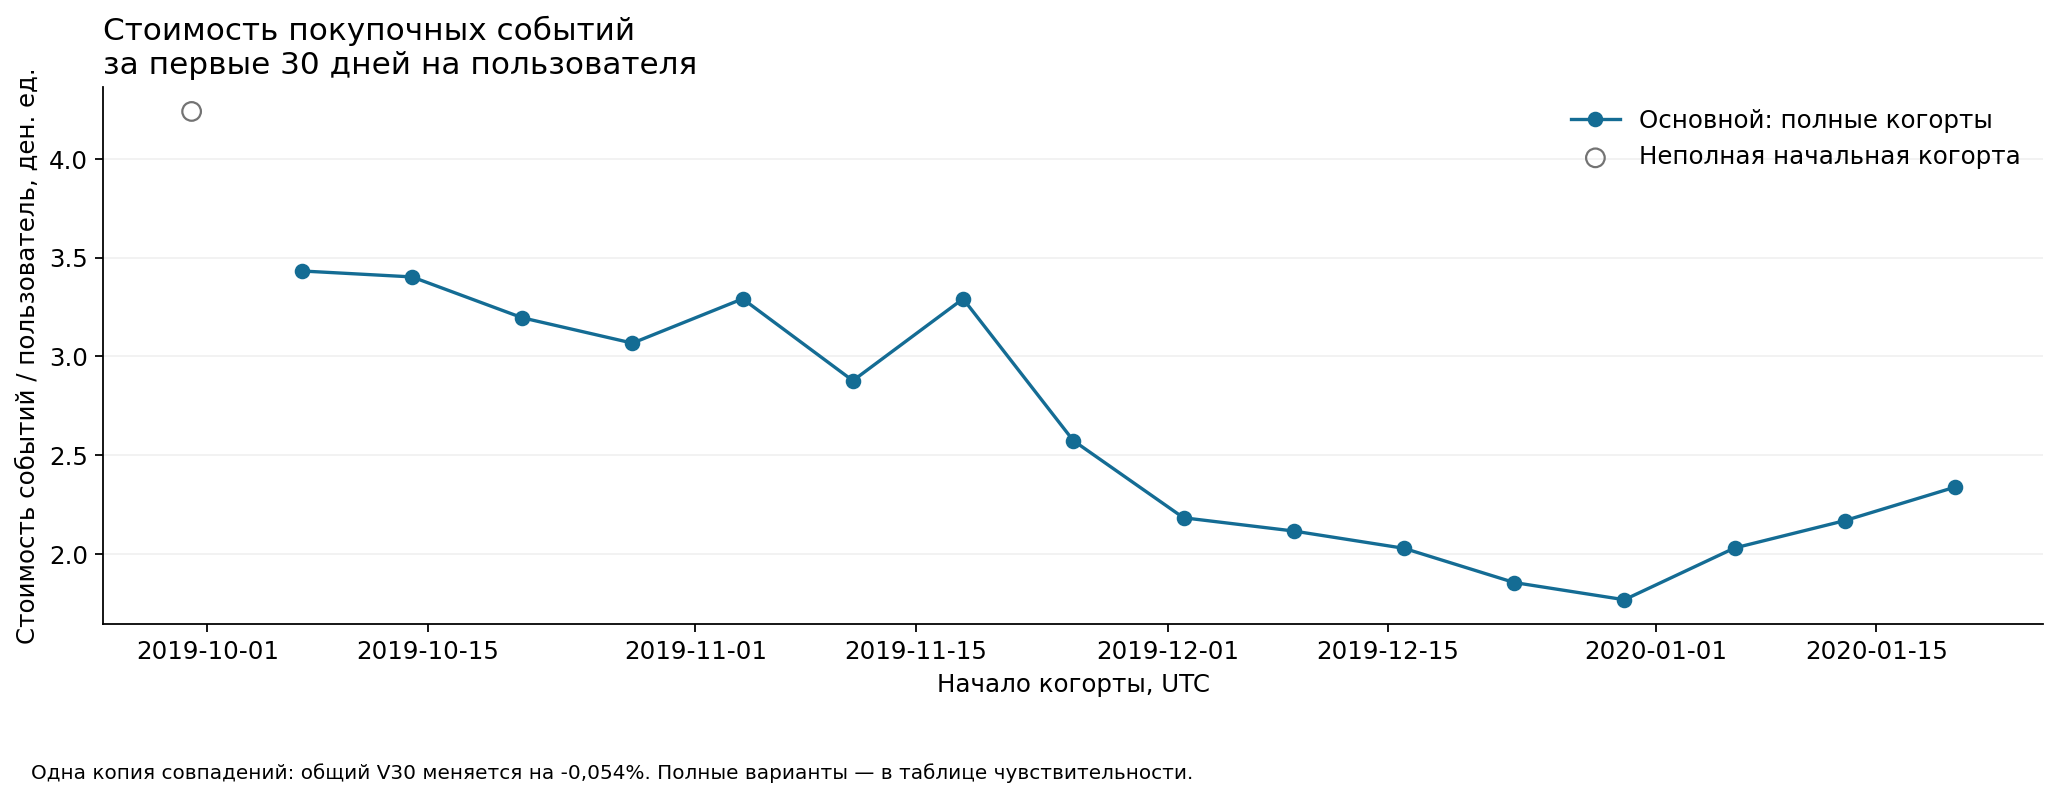

### value30_sensitivity

,Вариант,V30,"Изменение к основному, %"
0,Основной,2.6315,0.0000
1,Исходные цены с отрицательными,2.6297,-0.0678
2,Одна копия полного совпадения,2.6301,-0.0540
3,"Ограничение P99,9",2.5996,-1.2109


### Пояснение к диагностике

**Что измерено деньгами.** Для 1 170 587 пользователей полных зрелых когорт средний `V30` = **2,6315** денежных единиц на пользователя. Покупочное событие за 30 дней есть у **6,02%** пользователей; медиана пользовательской стоимости = **0,00**, P99 = **66,14**. Среднее не описывает типичного пользователя. Исходные отрицательные цены меняют среднее на **-0,0678%**, сценарий одной копии совпадения — на **-0,05%**, ограничение P99,9 — на **-1,21%**. В этих проверенных сценариях денежное среднее меняется умеренно; это не устраняет неопределённость оплаты, количества, возвратов и маржи. Совпадения во всём наборе не означают такой же процент искажения покупочной стоимости. Эти сценарии не затрагивают факт пользовательской активности и покупки.

### Влияние частотной эвристики

,Метрика,Пользователей,Помечено,Основной,Без эвристической группы,Разница,Единица
0,CR7,1462284,167,4.7746,4.7713,-0.0033,п.п. для разницы; % для уровней
1,R4,1170587,142,3.3755,3.3715,-0.0040,п.п. для разницы; % для уровней
2,V30,1170587,142,2.6315,2.6025,-0.0290,ден. ед./польз.


... (5 outputs left out)

,Критерий,Статус,Подтверждение / ограничение
0,1. Продукт,Выполнено,"Контекст, аудитория, проблема, гипотеза и рабо..."
1,2. Данные и качество,Выполнено локально,"Все пять месяцев; пропуски, совпадения, цены, ..."
2,Лицензия и номер версии,Ограничено доступностью первоисточника,Точные условия и номер не подтверждены; снимок...
3,3. Определения,Выполнено,"Окна, знаменатели, зрелость, начало истории и ..."
4,4. Пирамида метрик,Предварительный риск-индикатор; защитная метри...,Три продуктовые метрики и ITT-покупка в дни 7–...
5,5. Трекинг,Выполнено,"Четыре наблюдаемых события; триггеры, параметр..."
6,6. Когортный retention,Выполнено,"Полные окна, размеры когорт, таблицы и график;..."
7,6. LTV/CAC,Частично,Синтетический сценарный расчёт CAC/LTV30 показ...
8,7. Этика,Выполнено в доступном объёме,"Описаны происхождение, неизвестность согласия,..."
9,8. Цели и проверка,Выполнено как постановка; риск-порог открыт,Три численные цели и план теста; для поздней п...


### Проверки текущего полного исполнения

,Проверка,Результат,Подробности
0,Архив присутствует,Пройдена,
1,SHA-256 архива,Пройдена,
2,Ровно пять исходных CSV,Пройдена,
3,Пять CSV совпадают с архивом: хэш и схема,Пройдена,[]
4,Импорт не теряет строки,Пройдена,
5,Преобразования без ошибок и округления цены,Пройдена,"[{'time_errors': 0, 'user_errors': 0, 'product..."
6,Известные типы событий,Пройдена,
7,Нет пропусков ключей активности,Пройдена,
8,Сохранение числа событий в агрегации,Пройдена,
9,Соединение не размножает user_days,Пройдена,


[Вернуться к резюме](#top) · Полные таблицы: outputs/tables/.

In [28]:
titles={
 'risk_summary':'Исторический прокси поздней покупочной активности',
 'runtime_versions':'Фактические версии среды','input_inventory':'Проверенные исходные файлы',
 'event_counts':'Число событий по типам','monthly_inventory':'Помесячное покрытие',
 'missing_values':'Пропуски','identifier_checks':'Проверки идентификаторов',
 'price_quality':'Цены по типам событий','duplicates_summary':'Полные совпадения строк',
 'duplicates_by_event':'Совпадения по событиям','suspicious_summary':'Частотные эвристики',
 'session_quality':'Качество технических сессий','session_ids_shared':'Общие ID сессий',
 'time_coverage':'Непрерывность дат','timestamp_boundaries':'Границы меток времени',
 'retention_summary':'Когортное удержание: расширенная таблица',
 'weekly_metrics':'Полные недели: числители и знаменатели',
 'basket_risk_definitions':'Диагностика редактирования корзины: разные единицы',
 'bedit_first_week_sensitivity':'Чувствительность редактирования корзины к первой неделе',
 'inactivity_sensitivity':'Наблюдаемая неактивность при разных окнах',
 'money_global_sensitivity':'Стоимость событий всех пяти месяцев',
 'money_cohorts':'Стоимость покупочных событий за первые 30 дней по зрелым когортам','heuristic_sensitivity':'Влияние частотной эвристики',
 'scenario_economics':'Сценарная экономика: синтетические поля','synthetic_channel_cac':'CAC условных синтетических каналов','scenario_ratio_matrix':'Сценарный LTV30/CAC для всей популяции','pa_s1_compliance':'Соответствие требованиям',
 'validation_report':'Проверки текущего полного исполнения'}
for name,frame in APPENDIX:
    display(Markdown('### '+titles.get(name,name)))
    display(frame)
display(Markdown('[Вернуться к резюме](#top) · Полные таблицы: outputs/tables/.'))